In [163]:
print("hello world")

hello world


# IMDb: Decoding What Makes a Movie Timeless

## 1. Business Context

IMDb's Top 700 represents a collection of highly ranked films based on IMDb's rating methodology. However, simply looking at the ranked list does not explain why certain movies achieve and sustain strong rating performance.

The objective of this analysis is to understand the factors associated with high Average IMDb Rating across different genres, eras, directors, countries, vote volumes, and movie characteristics.

This analysis will help the Content Insights team understand patterns that can support movie curation, hidden-gem discovery, and editorial storytelling.

## 1.2 Problem Statement

The key business question is:

**What movie characteristics and structural factors are associated with higher Average IMDb Rating within the IMDb Top 700?**

The analysis will examine the relationship between Average IMDb Rating and:

- Genre(s)
- Release Year / Era
- Director
- Country
- Votes
- Runtime
- Main Actors
- IMDb Rank

## 1.3 Objectives

The analysis aims to:

1. Deconstruct Average IMDb Rating across Genre(s), Era, Country, and Director.
2. Identify rating patterns across different movie segments.
3. Analyse the relationship between Votes, Runtime, and IMDb Rating.
4. Evaluate Director and Main Actor track record across the Top 700.
5. Examine country and regional representation.
6. Identify characteristics associated with exceptionally highly rated movies.
7. Translate the findings into actionable business insights and recommendations.

##  1.4 Key Metric and Supporting KPIs

### Primary Metric

**Average IMDb Rating**

Average IMDb Rating = Mean of IMDb Rating

This is the primary metric used to evaluate rating performance across different movie segments.

##  1.5 Supporting KPIs

- **Average Votes per Film** — measures audience engagement.
- **Director Frequency in Top 700** — measures repeated director representation.
- **Country Representation Rate** — measures the share of Top 700 movie records associated with each country.
- **IMDb Rank** — provides ranking context for the movies.
- **Runtime** — supporting movie characteristic.
- **Genre and Era** — segmentation dimensions.

 ##   1.6 Analytical Approach

The analysis will follow a structured approach:

**Data Understanding → Data Cleaning → Exploratory Data Analysis → Hypothesis Testing → Statistical Analysis → Key Findings → Business Recommendations**

All conclusions will be based on the observed data and statistical evidence. Correlation and regression results will be interpreted as associations and will not be treated as proof of causation.

In [164]:
import pandas as pd

In [165]:
df = pd.read_csv("IMDb_Top_700_Movies_2026.csv")

In [76]:
df.head()

,Rank,Title,Year,Genre(s),Director,Main Actor(s),Country,IMDb Rating,Votes,Runtime (mins)
0,1,The Shawshank Redemption,1994,Drama,Frank Darabont,Tim Robbins|Morgan Freeman|Bob Gunton,DK|AT,9.3,3219532,142
1,2,The Godfather,1972,Crime|Drama,Francis Ford Coppola,Marlon Brando|Al Pacino|James Caan,DK|AT,9.2,2244476,175
2,3,The Dark Knight,2008,Crime|Thriller,Christopher Nolan,Christian Bale|Heath Ledger|Aaron Eckhart,DK|LV,9.1,3205233,152
3,4,The Lord of the Rings: The Return of the King,2003,Adventure|Drama|Fantasy,Peter Jackson,Elijah Wood|Viggo Mortensen|Ian McKellen,DK|MK,9.0,2181911,201
4,5,Schindler's List,1993,Biography|Drama|History,Steven Spielberg,Liam Neeson|Ralph Fiennes|Ben Kingsley,DK|LV,9.0,1595992,195


##   2 Dataset Understanding

The dataset contains **700 movie records** from the IMDb Top 700 list.

Each row represents one movie, while the columns provide information about its ranking, release year, genre, director, cast, country, IMDb Rating, number of votes, and runtime.

### Key Variables

| Variable | Description | Analytical Role |
|---|---|---|
| Rank | IMDb ranking position | Ranking context |
| Title | Movie title | Movie identifier |
| Year | Movie release year | Time/Era analysis |
| Genre(s) | One or more movie genres | Genre segmentation |
| Director | Movie director | Director track record |
| Main Actor(s) | Leading actors | Cast track record |
| Country | Country/countries associated with the movie | Geographic analysis |
| IMDb Rating | Movie rating | Primary metric |
| Votes | Number of user votes | Audience engagement |
| Runtime (mins) | Movie duration | Supporting numerical variable |

The primary outcome variable for this analysis is **IMDb Rating**, while Votes, Runtime, Genre(s), Year, Director, Country, and Main Actor(s) are used to understand the factors associated with rating performance.

In [77]:
df.columns

Index(['Rank', 'Title', 'Year', 'Genre(s)', 'Director', 'Main Actor(s)',
       'Country', 'IMDb Rating', 'Votes', 'Runtime (mins)'],
      dtype='object')

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Rank            700 non-null    int64  
 1   Title           700 non-null    object 
 2   Year            700 non-null    int64  
 3   Genre(s)        700 non-null    object 
 4   Director        700 non-null    object 
 5   Main Actor(s)   690 non-null    object 
 6   Country         700 non-null    object 
 7   IMDb Rating     700 non-null    float64
 8   Votes           700 non-null    int64  
 9   Runtime (mins)  700 non-null    int64  
dtypes: float64(1), int64(4), object(5)
memory usage: 54.8+ KB


## 2.2 Checking Missing Values

Before moving to the analysis, I check the dataset for missing values.

Missing values can affect calculations and comparisons, so this step helps identify whether any important analytical variables require additional treatment.

I will examine the missing values column by column and determine whether they need to be handled before continuing with the analysis.

In [146]:
df.isnull().sum()

,0
Rank,0
Title,0
Year,0
Genre(s),0
Director,0
Main Actor(s),10
Country,0
IMDb Rating,0
Votes,0
Runtime (mins),0


### Interpretation

The dataset contains 10 missing values in the `Main Actor(s)` column, while all other columns have no missing values.

Since `IMDb Rating`, `Votes`, `Year`, and `Runtime (mins)` have no missing values, the missing actor information does not affect the core rating analysis.

The 10 missing actor observations will be handled appropriately when performing actor-specific analysis.

In [147]:
df['Main Actor(s)'].isnull().sum()

np.int64(10)

In [166]:
df.duplicated().sum()

np.int64(0)

### Interpretation

The `Main Actor(s)` column contains 10 missing observations. This represents a small portion of the 700 movie records.

Since the missing values are limited to actor information and the primary metric `IMDb Rating` has no missing values, these records will be retained for the core analysis.

For actor-specific analysis, the missing actor observations will naturally be excluded.

In [152]:
df[['Year','IMDb Rating','Votes','Runtime (mins)']].describe()

,Year,IMDb Rating,Votes,Runtime (mins)
count,700.000000,700.000000,7.000000e+02,700.000000
mean,1998.038571,8.000143,5.330973e+05,127.360000
std,21.347254,0.316657,4.692722e+05,29.101895
min,1921.000000,7.500000,5.196400e+04,68.000000
25%,1989.000000,7.800000,1.982610e+05,106.000000
50%,2004.000000,8.000000,3.988475e+05,123.000000
75%,2013.250000,8.200000,7.285130e+05,143.000000
max,2026.000000,9.300000,3.219532e+06,321.000000


### Interpretation

The descriptive statistics provide an overall view of the 700 movies in the IMDb Top 700 dataset.

- The average IMDb Rating is approximately **8.00**, with ratings ranging from **7.5 to 9.3**.
- The average number of votes is approximately **533K**, while the maximum reaches about **3.22 million** votes.
- The movies have an average runtime of approximately **127 minutes**, with runtimes ranging from **68 to 321 minutes**.
- The movies span from **1921 to 2026**, showing that the dataset covers films across a wide range of eras.
- The difference between the mean and median for Votes indicates that the vote distribution is not evenly spread, with some movies receiving substantially more votes than others.

These statistics establish the baseline for the deeper analysis of how ratings vary across genres, decades, directors, countries, votes, and runtime.

## 2.3 Duplicate Record Check

Before conducting further analysis, I need to verify whether any movie records are duplicated.

Duplicate records could give certain movies more weight in averages and group-level comparisons, which could distort the analysis.

I will check:
1. Complete duplicate rows
2. Duplicate movies using the combination of **Title and Year**

This helps confirm that each movie is represented only once in the dataset.

In [153]:
Q1 = df['Runtime (mins)'].quantile(0.25)
Q3 = df['Runtime (mins)'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

outliers = df[
    (df['Runtime (mins)'] < lower_bound) |
    (df['Runtime (mins)'] > upper_bound)
]

outliers[['Title', 'Year', 'Runtime (mins)']]

Lower Bound: 50.5
Upper Bound: 198.5


,Title,Year,Runtime (mins)
3,The Lord of the Rings: The Return of the King,2003,201
5,The Godfather Part II,1974,202
55,Seven Samurai,1954,207
118,Once Upon a Time in America,1984,229
140,Lawrence of Arabia,1962,227
170,Gone with the Wind,1939,238
246,Ben-Hur,1959,212
264,Zack Snyder's Justice League,2021,242
328,Dhurandhar,2025,214
342,The Irishman,2019,209


### Interpretation

The IQR method identified 14 movies with runtimes above the upper bound of 198.5 minutes.

These observations are treated as potential statistical outliers because their runtimes are unusually high compared with the rest of the dataset. However, a high runtime does not necessarily indicate a data-quality error.

The identified movies include well-known long-format films such as *The Lord of the Rings: The Return of the King*, *The Godfather Part II*, *Lawrence of Arabia*, and *Gangs of Wasseypur*. Therefore, these values appear to represent genuine movie runtimes rather than incorrect data entries.

**Decision:** The runtime outliers will be retained in the dataset because they are valid observations. Removing them could distort the analysis of the relationship between Runtime and IMDb Rating.

In [154]:
outliers[['Title', 'Year', 'IMDb Rating', 'Votes', 'Runtime (mins)']].sort_values(
    by='Runtime (mins)', ascending=False
)

,Title,Year,IMDb Rating,Votes,Runtime (mins)
410,Gangs of Wasseypur,2012,8.2,115190,321
534,Kill Bill: The Whole Bloody Affair,2004,8.7,51964,253
264,Zack Snyder's Justice League,2021,7.9,477469,242
170,Gone with the Wind,1939,8.2,357435,238
660,Dhurandhar: The Revenge,2026,8.2,68782,235
118,Once Upon a Time in America,1984,8.3,410545,229
140,Lawrence of Arabia,1962,8.3,344245,227
420,Lagaan: Once Upon a Time in India,2001,8.1,130160,224
328,Dhurandhar,2025,8.2,148163,214
246,Ben-Hur,1959,8.1,272507,212


In [157]:
df.duplicated(subset=['Title', 'Year']).sum()


np.int64(0)

### Interpretation

The duplicate check found **0 duplicate records** based on the combination of Title and Year.

This indicates that each movie appears only once in the dataset when identified by its title and release year. Therefore, duplicate movie records are not expected to distort the subsequent rating, vote, genre, director, country, or runtime analysis.

**Decision:** No duplicate records need to be removed based on Title and Year.

In [167]:
categorical_cols = ['Genre(s)', 'Director', 'Country']

for col in categorical_cols:
    print(f"\n{col}:")
    print("Missing:", df[col].isnull().sum())
    print("Unique values:", df[col].nunique())


Genre(s):
Missing: 0
Unique values: 179

Director:
Missing: 0
Unique values: 407

Country:
Missing: 0
Unique values: 40


### Interpretation

The categorical fields required for the core analysis contain no missing values.

- **Genre(s):** 0 missing values with 179 unique combinations.
- **Director:** 0 missing values with 407 unique directors.
- **Country:** 0 missing values with 40 unique country codes.

The high number of unique Genre(s) values is expected because a movie can belong to multiple genres, and different genre combinations are stored as separate values.

**Decision:** No missing-value treatment is required for Genre(s), Director, or Country. For genre and country analysis, the multi-value fields will be split and analysed separately so that individual genres and countries can be compared correctly.

## 2.4 Handling Multiple Country Entries

Before performing country-level analysis, I checked whether any movie is associated with more than one country.

Some movies contain multiple country codes separated by `|`. If these combinations are treated as one category, country-level movie counts and average ratings could become misleading.

Therefore, I will identify these multi-country records first and later split them into individual country entries for analysis.

In [87]:
df[df['Main Actor(s)'].isnull()][
    ['Title', 'Year', 'Director', 'Country']
]

,Title,Year,Director,Country
426,Senna,2010,Asif Kapadia,PT|NO
446,20 Days in Mariupol,2023,Mstyslav Chernov,DK|PT
518,Bowling for Columbine,2002,Michael Moore,PH|PT
534,Kill Bill: The Whole Bloody Affair,2004,Quentin Tarantino,DK|PH
556,Inside Job,2010,Charles Ferguson,DK|PH
592,Free Solo,2018,Jimmy Chin|Elizabeth Chai Vasarhelyi,DK|AT
593,Searching for Sugar Man,2012,Malik Bendjelloul,PT|ZA
611,Flow,2024,Gints Zilbalodis,DK|LV
671,Blackfish,2013,Gabriela Cowperthwaite,DK|PH
696,The Cove,2009,Louie Psihoyos,DK|PT


### Interpretation

The Country field contains multiple country codes for some movies, indicating that these movies are associated with more than one country.

The identified records contain two country codes separated by `|`. Treating these combinations as a single category would make country-level comparisons less accurate.

**Decision:** The multi-country entries will be split into individual country codes before calculating country-level movie counts, average ratings, and average votes. This ensures that each associated country is represented in the analysis.

In [88]:
df['Genre(s)'].str.split('|').explode().value_counts()

,count
Genre(s),
Drama,473
Adventure,176
Action,160
Crime,156
Comedy,149
Thriller,106
Mystery,80
Biography,78
Romance,72


### Interpretation

The genre frequency analysis shows how different genres are represented across the IMDb Top 700 dataset.

- **Drama** is the most frequently represented genre, appearing in **473 movies**.
- **Adventure, Action, Crime, and Comedy** are also highly represented, with more than 140 movie appearances each.
- Genres such as **Musical, Documentary, Film-Noir, and Western** have relatively fewer appearances.
- These counts represent genre appearances rather than unique movies because a single movie can belong to multiple genres.

This distribution is important because genres with very few observations may produce unstable average-rating comparisons.

**Decision:** For the next genre-level rating analysis, I will focus on genres with a sufficient number of movie observations rather than interpreting very small groups.

In [89]:
df['Genre(s)'] = df['Genre(s)'].str.split('|')

df[['Title', 'Genre(s)']].head(10)

,Title,Genre(s)
0,The Shawshank Redemption,[Drama]
1,The Godfather,"[Crime, Drama]"
2,The Dark Knight,"[Crime, Thriller]"
3,The Lord of the Rings: The Return of the King,"[Adventure, Drama, Fantasy]"
4,Schindler's List,"[Biography, Drama, History]"
5,The Godfather Part II,"[Crime, Drama]"
6,The Lord of the Rings: The Fellowship of the Ring,"[Adventure, Drama, Fantasy]"
7,12 Angry Men,"[Crime, Drama]"
8,Inception,"[Adventure, Sci-Fi, Thriller]"
9,Fight Club,"[Crime, Drama, Thriller]"


### Interpretation

The `Genre(s)` column has been successfully split into individual genre categories.

For example:
- *The Shawshank Redemption* is classified as Drama.
- *The Godfather* is classified as Crime and Drama.
- *The Lord of the Rings: The Return of the King* is classified as Adventure, Drama, and Fantasy.

This transformation allows each individual genre to be analysed separately instead of treating combinations such as `Crime|Drama` as one unique category.

**Decision:** The transformed genre data will be used to compare movie counts, average IMDb ratings, and average votes across individual genres.

In [160]:
['Action', 'Adventure', 'Drama']

['Action', 'Adventure', 'Drama']

In [161]:
genre_df = df.explode('Genre(s)')

genre_analysis = (
    genre_df.groupby('Genre(s)')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Avg_Rating', ascending=False)
)

genre_analysis

,Movie_Count,Avg_Rating,Avg_Votes
Genre(s),,,
Documentary,8,8.237500,84884.125000
War,32,8.175000,473960.281250
Musical,7,8.128571,154630.714286
Western,13,8.123077,490463.384615
Film-Noir,8,8.037500,162590.000000
Biography,78,8.037179,426798.153846
Drama,473,8.028330,480990.642706
Animation,63,8.017460,500848.047619
Crime,156,8.014744,549694.294872


### Interpretation

The genre-level analysis shows noticeable variation in average IMDb Rating across genres.

- **Documentary** has the highest average rating at approximately **8.24**, followed by **War (8.18)** and **Musical (8.13)**.
- **Drama** has a large representation with **473 movie appearances** and an average rating of approximately **8.03**.
- **Action, Thriller, and Horror** have comparatively lower average ratings in this dataset, at approximately **7.92, 7.92, and 7.89**, respectively.
- Some genres have very small sample sizes, such as Musical (7) and Documentary (8). Therefore, their higher average ratings should be interpreted cautiously.
- Genres such as Drama, Adventure, Action, and Crime have much larger sample sizes, making their averages more useful for broad comparisons within this dataset.

The analysis also shows that a higher average rating does not necessarily correspond to a higher average number of votes. For example, Sci-Fi has a relatively high average vote count of approximately 879K but an average rating of approximately 7.99.

**Decision:** Genre-level comparisons will consider both average IMDb Rating and the number of movie observations. Small-sample genres will be treated as directional findings rather than strong conclusions.

In [92]:
genre_analysis.head(10)

,Movie_Count,Avg_Rating,Avg_Votes
Genre(s),,,
Documentary,8,8.237500,84884.125000
War,32,8.175000,473960.281250
Musical,7,8.128571,154630.714286
Western,13,8.123077,490463.384615
Film-Noir,8,8.037500,162590.000000
Biography,78,8.037179,426798.153846
Drama,473,8.028330,480990.642706
Animation,63,8.017460,500848.047619
Crime,156,8.014744,549694.294872


### Interpretation

The genre-level analysis shows noticeable variation in average IMDb Rating across genres.

- **Documentary** has the highest average rating at approximately **8.24**, followed by **War (8.18)** and **Musical (8.13)**.
- **Drama** has a large representation with **473 movie appearances** and an average rating of approximately **8.03**.
- **Action, Thriller, and Horror** have comparatively lower average ratings in this dataset, at approximately **7.92, 7.92, and 7.89**, respectively.
- Some genres have very small sample sizes, such as Musical (7) and Documentary (8). Therefore, their higher average ratings should be interpreted cautiously.
- Genres such as Drama, Adventure, Action, and Crime have much larger sample sizes, making their averages more useful for broad comparisons within this dataset.

The analysis also shows that a higher average rating does not necessarily correspond to a higher average number of votes. For example, Sci-Fi has a relatively high average vote count of approximately 879K but an average rating of approximately 7.99.

**Decision:** Genre-level comparisons will consider both average IMDb Rating and the number of movie observations. Small-sample genres will be treated as directional findings rather than strong conclusions.

In [93]:
genre_analysis_filtered = genre_analysis[
    genre_analysis['Movie_Count'] >= 10
].sort_values('Avg_Rating', ascending=False)

genre_analysis_filtered

,Movie_Count,Avg_Rating,Avg_Votes
Genre(s),,,
War,32,8.175000,473960.281250
Western,13,8.123077,490463.384615
Biography,78,8.037179,426798.153846
Drama,473,8.028330,480990.642706
Animation,63,8.017460,500848.047619
Crime,156,8.014744,549694.294872
Music,16,8.006250,392191.125000
Sport,16,7.993750,343668.000000
Sci-Fi,62,7.991935,878560.419355


## 3 Genre Performance Analysis

To understand how movie performance varies across different genres, I will compare the **Average IMDb Rating**, **Average Votes**, and **Number of Movies** for each genre.

This analysis will help identify:

- Which genres have higher or lower average IMDb Ratings
- Which genres receive higher audience engagement, measured by Average Votes
- How strongly each genre is represented in the IMDb Top 700 dataset

Since movies can belong to multiple genres, the genre data has been split into individual genre categories before calculating these metrics.

This analysis will help determine whether highly rated genres also tend to have stronger audience engagement.

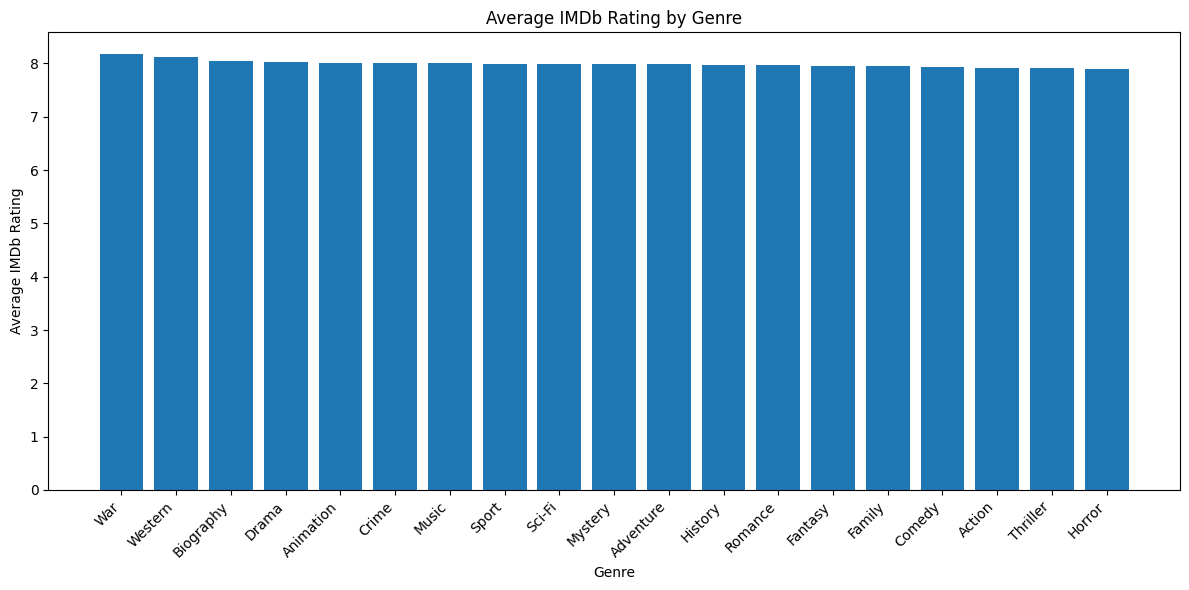

In [94]:
import matplotlib.pyplot as plt

top_genres = genre_analysis_filtered.sort_values(
    'Avg_Rating', ascending=False
)

plt.figure(figsize=(12, 6))

plt.bar(
    top_genres.index,
    top_genres['Avg_Rating']
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Genre')
plt.ylabel('Average IMDb Rating')
plt.title('Average IMDb Rating by Genre')
plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating across genres with at least 10 movie appearances.

War has the highest average IMDb Rating among the displayed genres, followed by Western and Biography. On the other hand, Horror, Thriller, and Action appear toward the lower end of the comparison.

The differences between most genres are relatively small, with average ratings concentrated around the 8.0 level. Therefore, genre appears to be associated with some variation in average IMDb Rating, but the chart alone does not establish that genre causes higher or lower ratings.

Genres with larger numbers of movie observations provide a more stable basis for comparison than genres with relatively fewer observations.

**Decision:** Genre will be retained as an important segmentation variable for further analysis, while differences in small-sample genres will be interpreted cautiously.

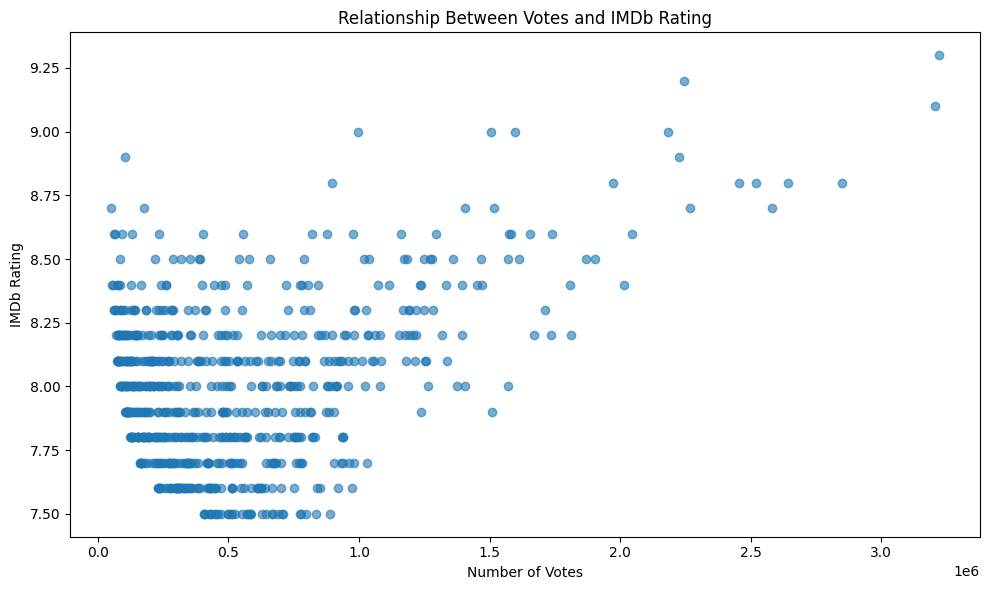

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Votes'],
    df['IMDb Rating'],
    alpha=0.6
)

plt.xlabel('Number of Votes')
plt.ylabel('IMDb Rating')
plt.title('Relationship Between Votes and IMDb Rating')

plt.tight_layout()
plt.show()

### Chart Interpretation

The scatter plot shows the relationship between the number of Votes and IMDb Rating across the movies in the dataset.

The points show a generally positive pattern: movies with a higher number of votes tend to have somewhat higher IMDb Ratings. However, the points are widely dispersed, which indicates that the relationship is not very strong.

The earlier correlation analysis gives a Pearson correlation of approximately **0.405**, indicating a moderate positive association between Votes and IMDb Rating.

This means that popularity, measured through the number of votes, is associated with higher ratings to some extent, but votes alone do not explain a movie's IMDb Rating.

**Decision:** Votes will be retained as an important supporting variable for understanding movie popularity and its association with IMDb Rating. However, it will not be treated as a direct cause of higher ratings.

## 3.1 Relationship Between Votes and IMDb Rating

To understand whether movie popularity is associated with IMDb Rating, I will examine the relationship between the number of Votes and IMDb Rating.

The number of Votes represents how many users have rated a movie, while IMDb Rating represents the average rating received by the movie.

I will use a **scatter plot** to visually examine the relationship and calculate the **Pearson correlation coefficient** to measure the strength and direction of the linear association.

A positive correlation would indicate that movies with more votes tend to have higher ratings, while a correlation close to zero would indicate a weak linear relationship.

In [96]:
correlation = df['Votes'].corr(df['IMDb Rating'])

print("Correlation between Votes and IMDb Rating:", correlation)



Correlation between Votes and IMDb Rating: 0.40484310150467223


### Correlation Interpretation

The Pearson correlation between Votes and IMDb Rating is **0.405**.

This indicates a **moderate positive relationship** between the number of votes and IMDb Rating in the dataset. In general, movies with more votes tend to have somewhat higher IMDb Ratings.

However, the correlation is not close to 1, which means Votes do not fully explain differences in IMDb Rating. Other factors may also be associated with a movie's rating.

Correlation measures association and does not establish a causal relationship between Votes and IMDb Rating.

**Decision:** Votes will be retained as an important supporting variable for further analysis, but it will not be treated as a direct cause of higher IMDb Ratings.

## 3.2 IMDb Rating Trends Across Decades

To understand how highly rated movies are distributed across different time periods, I will compare movies by decade.

For each decade, I will examine:
- Number of movies in the Top 700
- Average IMDb Rating
- Average number of Votes

This analysis will help identify whether the rating profile of highly ranked movies has changed across different eras and whether movie popularity, measured by Votes, varies by decade.

In [97]:
df['Decade'] = (df['Year'] // 10) * 10

decade_analysis = (
    df.groupby('Decade')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_index()
)

decade_analysis

,Movie_Count,Avg_Rating,Avg_Votes
Decade,,,
1920,5,8.080000,141474.400000
1930,8,8.175000,250776.500000
1940,14,8.171429,248892.785714
1950,29,8.172414,238831.689655
1960,31,8.138710,273036.258065
1970,34,8.091176,524364.764706
1980,61,8.008197,478850.721311
1990,95,8.057895,702084.305263
2000,177,7.924294,608729.333333


### Interpretation

The decade-level analysis shows variation in both the number of Top 700 movies and their average IMDb Ratings.

The **2000s and 2010s** have the highest representation, with 177 and 181 movies respectively. Their average IMDb Ratings are approximately **7.92 and 7.93**, which are lower than several earlier decades.

The **1930s, 1940s, and 1950s** show relatively high average ratings, around **8.17**, although these decades contain considerably fewer movies.

The **2020s** have 65 movies with an average rating of approximately **8.06**, while the 1990s have 95 movies with an average rating of approximately **8.06**.

Average Votes are highest in the **1990s**, at approximately **702K**, followed by the 2000s and 2010s at around **609K and 605K** respectively.

Because some earlier decades have small numbers of movies, their average ratings should be interpreted cautiously.

**Decision:** Decade will be retained as an important time-based segmentation variable. Both movie count and average rating will be considered when comparing different eras.

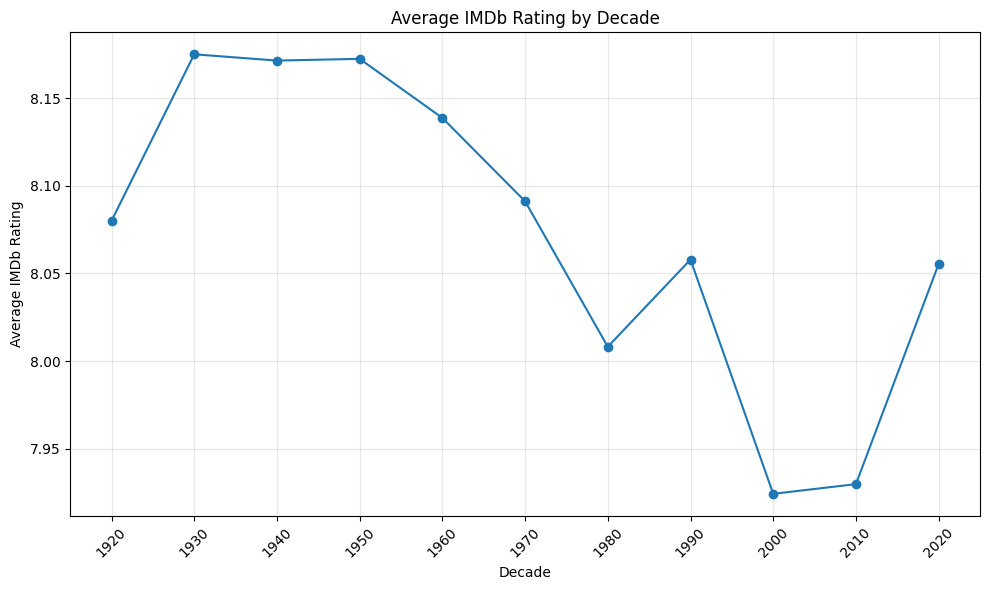

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    decade_analysis.index,
    decade_analysis['Avg_Rating'],
    marker='o'
)

plt.xlabel('Decade')
plt.ylabel('Average IMDb Rating')
plt.title('Average IMDb Rating by Decade')

plt.xticks(decade_analysis.index, rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Chart Interpretation

The line chart shows how the average IMDb Rating varies across different decades.

The average rating is relatively high from the **1930s to the 1960s**, remaining above 8.13 for these decades. The rating then shows a gradual decline through the 1970s and 1980s.

The average IMDb Rating reaches lower levels in the **2000s and 2010s**, at approximately 7.92 and 7.93 respectively. It then increases again in the 2020s to approximately 8.06.

The chart indicates that average IMDb Rating varies across different eras. However, the number of movies represented in each decade is also important, particularly for earlier decades with fewer observations.

**Decision:** Decade will be retained as an important time-based variable for further analysis, while rating differences will be interpreted together with the number of movies in each decade.

## 3.3 Director Track Record Analysis

To understand whether repeated appearances in the IMDb Top 700 are associated with higher average ratings, I will analyse directors based on their number of movie appearances.

For each director, I will examine:
- Number of movies in the Top 700
- Average IMDb Rating
- Average number of Votes

To avoid drawing conclusions from directors with only one or two movies, the analysis focuses on directors with at least **3 movie appearances**.

This analysis helps evaluate whether directors with a stronger track record of Top 700 appearances also show consistently high average ratings.

In [99]:
director_analysis = (
    df.groupby('Director')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Movie_Count', ascending=False)
)

director_analysis.head(20)

,Movie_Count,Avg_Rating,Avg_Votes
Director,,,
Steven Spielberg,12,8.066667,8.903054e+05
Martin Scorsese,11,8.063636,9.147289e+05
Quentin Tarantino,10,8.170000,1.169491e+06
Stanley Kubrick,10,8.120000,5.518008e+05
Christopher Nolan,10,8.460000,1.770058e+06
Alfred Hitchcock,9,8.133333,3.321999e+05
David Fincher,8,8.037500,1.141662e+06
Denis Villeneuve,7,8.071429,7.501567e+05
Hayao Miyazaki,7,8.142857,4.301341e+05


### Interpretation

The director-level analysis shows variation in average IMDb Rating among directors with at least 3 movies in the Top 700.

Francis Ford Coppola has an average rating of **8.53** across 4 movies, while Christopher Nolan and Peter Jackson both have an average rating of **8.46** across 10 and 5 movies respectively.

Directors with a larger number of Top 700 appearances, such as Christopher Nolan, Quentin Tarantino, and Stanley Kubrick, provide a stronger basis for evaluating consistency than directors with only 3 appearances.

The results also show that a higher number of appearances does not automatically correspond to a higher average rating. For example, directors with 3–5 appearances can also have high average ratings.

Average Votes also vary substantially across directors, indicating differences in audience engagement.

**Decision:** Director track record will be retained as an important analytical dimension. Both the number of appearances and average rating will be considered together rather than evaluating directors only on their average rating.

### Director-Level Rating Comparison

To visually compare director-level performance, I will plot the average IMDb Rating for directors with at least 3 movies in the Top 700.

A horizontal bar chart is used because there are multiple directors and their names are relatively long. This makes the comparison easier to read.

The chart will help identify differences in average rating while the accompanying movie count provides context for the strength of each director's track record.

In [100]:
director_analysis_filtered = director_analysis[
    director_analysis['Movie_Count'] >= 3
].sort_values('Avg_Rating', ascending=False)

director_analysis_filtered.head(20)


,Movie_Count,Avg_Rating,Avg_Votes
Director,,,
Francis Ford Coppola,4,8.525000,1.245939e+06
Christopher Nolan,10,8.460000,1.770058e+06
Peter Jackson,5,8.460000,1.614506e+06
Sidney Lumet,3,8.366667,4.921113e+05
Charles Chaplin,5,8.340000,2.078512e+05
Sergio Leone,5,8.340000,4.502530e+05
Billy Wilder,5,8.320000,2.274420e+05
Akira Kurosawa,6,8.300000,1.793375e+05
Frank Capra,3,8.266667,2.691667e+05


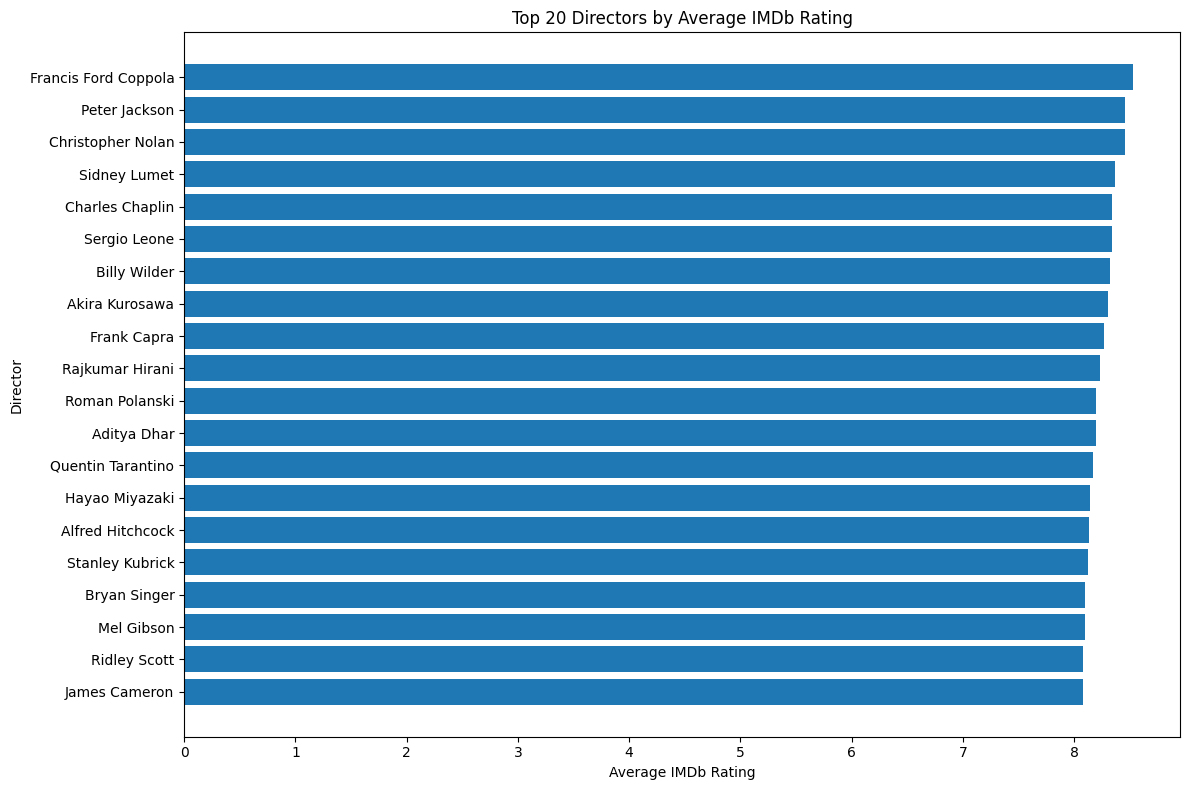

In [101]:
import matplotlib.pyplot as plt

top_directors = director_analysis_filtered.head(20).sort_values(
    'Avg_Rating',
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_directors.index,
    top_directors['Avg_Rating']
)

plt.xlabel('Average IMDb Rating')
plt.ylabel('Director')
plt.title('Top 20 Directors by Average IMDb Rating')

plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating of the 20 selected directors with at least 3 movies in the Top 700.

Francis Ford Coppola has the highest average rating in this selected group at approximately **8.53**. Peter Jackson and Christopher Nolan follow at approximately **8.46**.

The chart also shows that the average ratings of the selected directors are relatively close, with most values concentrated around the 8.0–8.5 range.

However, the number of movies represented by each director varies. For example, Christopher Nolan has 10 movies in the dataset, while some directors have only 3 movies. Therefore, average ratings based on a small number of movies should be interpreted cautiously.

**Decision:** Director-level analysis will consider both average IMDb Rating and movie count to evaluate track record rather than relying on rating alone.

In [102]:
country_analysis = (
    df.groupby('Country')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Movie_Count', ascending=False)
)

country_analysis.head(20)

,Movie_Count,Avg_Rating,Avg_Votes
Country,,,
DK|AT,133,8.062406,5.079608e+05
DK|LV,116,8.019828,6.008024e+05
LV|DK,90,8.006667,6.303394e+05
DK|PH,77,7.967532,4.809620e+05
LV|PH,61,7.863934,7.564256e+05
PH|PT,52,7.903846,5.493989e+05
DK|PT,40,8.040000,1.921687e+05
LV|AT,28,7.832143,5.894274e+05
AT|PH,20,8.025000,5.066160e+05


In [103]:
country_df = df.copy()

country_df['Country'] = country_df['Country'].str.split('|')

country_df = country_df.explode('Country')

country_analysis = (
    country_df.groupby('Country')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Movie_Count', ascending=False)
)

country_analysis.head(20)

,Movie_Count,Avg_Rating,Avg_Votes
Country,,,
DK,471,8.025053,5.338538e+05
LV,308,7.959091,6.396492e+05
PH,230,7.946957,5.444596e+05
AT,188,8.023404,5.131324e+05
PT,111,7.957658,3.636828e+05
ZA,38,8.150000,1.317912e+05
MK,15,8.053333,1.080551e+06
CR,8,8.062500,6.501845e+05
AU,8,8.187500,1.267780e+05


### Interpretation

The country-level analysis shows differences in movie representation, average IMDb Rating, and average Votes across the individual country codes.

DK has the highest number of movie appearances with **471**, followed by LV with **308**, PH with **230**, and AT with **188**.

Some countries have relatively high average ratings, such as AR (**8.27**), NZ (**8.43**), AU (**8.19**), and IN (**8.90**). However, several of these countries have very small numbers of movie observations.

For example, IN has only **1 movie**, while NZ and AR have only **3 movies** each. Therefore, their high average ratings should not be treated as strong evidence of a country-level pattern.

Countries with larger movie counts provide a more stable basis for comparison. The results also show variation in average Votes across countries.

**Decision:** Country will be retained as an important segmentation variable. For meaningful comparison, the next country-level visualization will focus on countries with a sufficient number of movie appearances, while small-sample countries will be interpreted cautiously.

In [104]:
country_analysis_filtered = country_analysis[
    country_analysis['Movie_Count'] >= 5
].sort_values('Avg_Rating', ascending=False)

country_analysis_filtered

,Movie_Count,Avg_Rating,Avg_Votes
Country,,,
AU,8,8.187500,1.267780e+05
ZA,38,8.150000,1.317912e+05
CR,8,8.062500,6.501845e+05
MK,15,8.053333,1.080551e+06
DK,471,8.025053,5.338538e+05
AT,188,8.023404,5.131324e+05
LU,5,7.960000,8.081132e+05
LV,308,7.959091,6.396492e+05
PT,111,7.957658,3.636828e+05


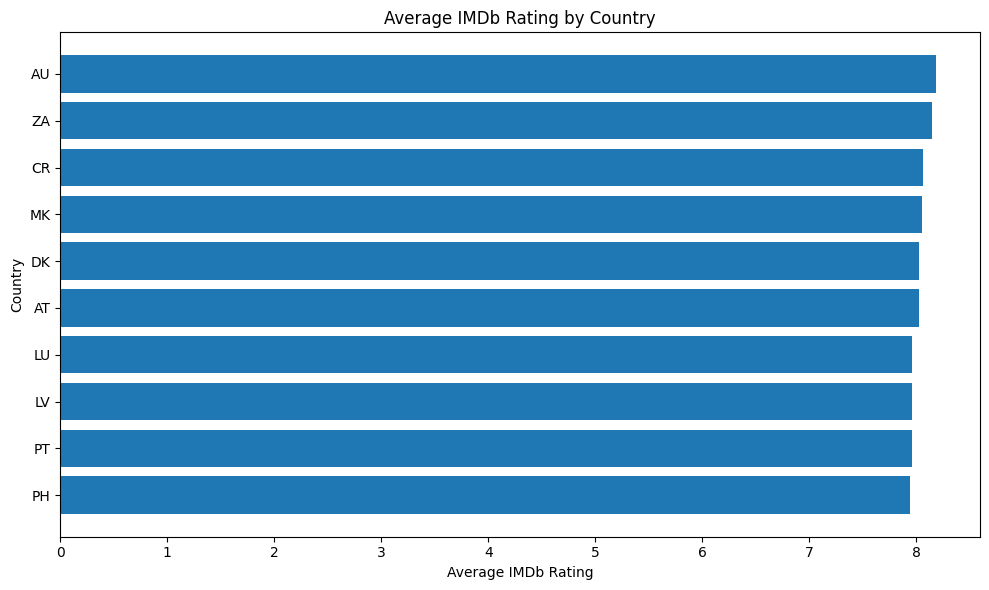

In [105]:
import matplotlib.pyplot as plt

top_countries = country_analysis_filtered.sort_values(
    'Avg_Rating',
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries.index,
    top_countries['Avg_Rating']
)

plt.xlabel('Average IMDb Rating')
plt.ylabel('Country')
plt.title('Average IMDb Rating by Country')

plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating across countries with at least 5 movie appearances in the dataset.

Among the displayed countries, **AU** has the highest average IMDb Rating at approximately **8.19**, followed by **ZA (8.15)** and **CR (8.06)**.

Countries with larger movie representation, such as **DK (471 movies)**, **LV (308 movies)**, **PH (230 movies)**, and **AT (188 movies)**, have average ratings close to 8.0.

The differences in average ratings across these countries are relatively small. Countries with fewer movie observations, such as AU and CR, should therefore be interpreted more cautiously than countries with much larger representation.

The chart also shows that country representation and average rating are not necessarily related. A country with fewer movies can have a higher average rating, while countries with many movies can have ratings closer to the overall dataset average.

**Decision:** Country will be retained as a segmentation variable for understanding regional representation and rating patterns. Country-level conclusions will be considered together with movie count to avoid overinterpreting small samples.

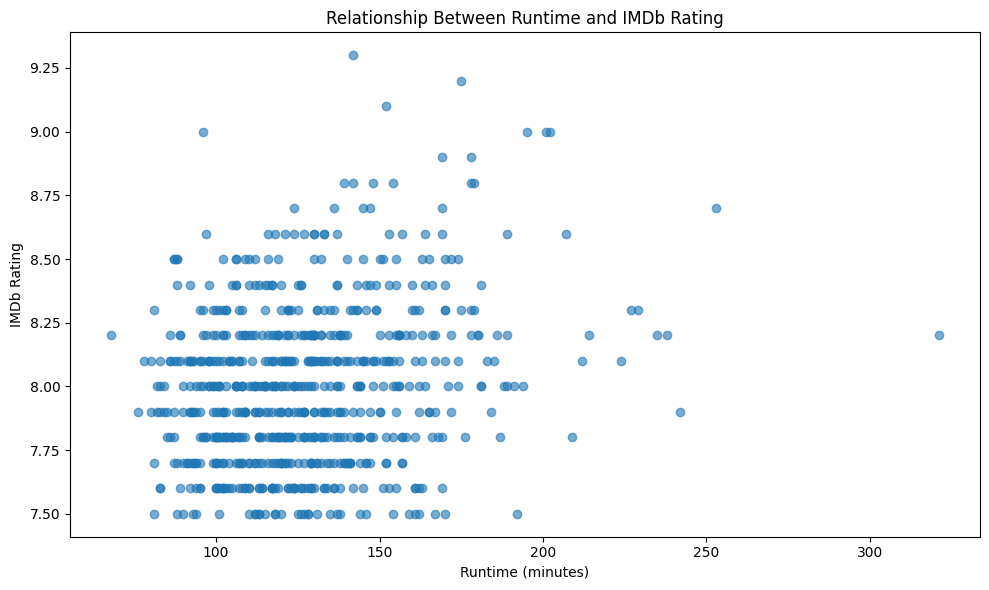

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    df['Runtime (mins)'],
    df['IMDb Rating'],
    alpha=0.6
)

plt.xlabel('Runtime (minutes)')
plt.ylabel('IMDb Rating')
plt.title('Relationship Between Runtime and IMDb Rating')

plt.tight_layout()
plt.show()

### Chart Interpretation

The scatter plot shows the relationship between Runtime and IMDb Rating across the movies in the dataset.

The points show a generally positive but weak pattern. Longer movies tend to have slightly higher IMDb Ratings, but the points are widely scattered across different runtime values.

The Pearson correlation between Runtime and IMDb Rating is approximately **0.239**, indicating a weak positive association.

The plot also contains some long-runtime movies with high ratings, but these individual observations do not establish that longer runtime causes higher ratings.

**Decision:** Runtime will be retained as a supporting variable for understanding differences in IMDb Rating. Since the relationship is weak, Runtime alone will not be considered a strong predictor of movie rating.

In [107]:
runtime_correlation = df['Runtime (mins)'].corr(df['IMDb Rating'])

print("Correlation between Runtime and IMDb Rating:", runtime_correlation)

Correlation between Runtime and IMDb Rating: 0.2387271691670901


In [108]:
from scipy.stats import ttest_ind

long_movies = df.loc[
    df['Runtime (mins)'] > 150,
    'IMDb Rating'
]

short_movies = df.loc[
    df['Runtime (mins)'] <= 150,
    'IMDb Rating'
]

t_stat, p_value = ttest_ind(
    long_movies,
    short_movies,
    equal_var=False
)

print("Long Movies Mean:", long_movies.mean())
print("Short Movies Mean:", short_movies.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

Long Movies Mean: 8.138345864661655
Short Movies Mean: 7.967724867724869
T-statistic: 4.91628792521023
P-value: 2.0491127391147833e-06


### Hypothesis Test Interpretation

The hypothesis test compares the average IMDb Rating of movies with Runtime greater than 150 minutes against movies with Runtime of 150 minutes or less.

The average IMDb Rating for long movies is **8.138**, compared with **7.968** for shorter/standard movies.

The Welch's t-test produced a t-statistic of **4.916** and a p-value of approximately **0.00000205**.

Since the p-value is substantially below the 5% significance level (α = 0.05), the null hypothesis is rejected.

This provides statistical evidence that the average IMDb Ratings of the two runtime groups are different in this dataset. The long-movie group has the higher observed average rating.

However, this result shows an association between runtime group and IMDb Rating; it does not establish that longer runtime causes higher ratings.

**Decision:** Runtime will be retained as a statistically relevant variable in the analysis. The relationship should still be interpreted alongside other factors such as genre, decade, votes, and director.

In [109]:
correlation_matrix = df[
    ['IMDb Rating', 'Votes', 'Runtime (mins)']
].corr()

correlation_matrix

,IMDb Rating,Votes,Runtime (mins)
IMDb Rating,1.000000,0.404843,0.238727
Votes,0.404843,1.000000,0.134519
Runtime (mins),0.238727,0.134519,1.000000


In [110]:
df['Vote_Category'] = pd.cut(
    df['Votes'],
    bins=[0, 100000, 300000, 600000, 1000000, float('inf')],
    labels=[
        'Below 100K',
        '100K–300K',
        '300K–600K',
        '600K–1M',
        'Above 1M'
    ]
)

vote_analysis = (
    df.groupby('Vote_Category', observed=True)
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Runtime=('Runtime (mins)', 'mean')
    )
)

vote_analysis

,Movie_Count,Avg_Rating,Avg_Runtime
Vote_Category,,,
Below 100K,45,8.228889,135.911111
100K–300K,233,7.970386,123.957082
300K–600K,192,7.850521,126.354167
600K–1M,144,7.936111,125.472222
Above 1M,86,8.402326,137.511628


### Interpretation

The vote-category analysis shows variation in average IMDb Rating across different levels of audience votes.

Movies with **Above 1M votes** have the highest average IMDb Rating at approximately **8.40**. Movies with **Below 100K votes** also have a relatively high average rating of approximately **8.23**, although this group contains only 45 movies.

The **300K–600K** vote category has the lowest average IMDb Rating at approximately **7.85**, followed by the **600K–1M** category at approximately **7.94**.

The results suggest that the relationship between audience votes and IMDb Rating is not simply linear across all vote categories. In particular, movies with more than 1 million votes show a noticeably higher average rating in this dataset.

Average Runtime also varies across vote categories, with movies having more than 1 million votes having an average runtime of approximately **138 minutes**.

However, vote-category differences should be interpreted together with movie count and other factors such as genre and decade.

**Decision:** Vote volume will be retained as an important analytical variable. The above-1M vote group will receive particular attention in the final analysis because it shows a substantially higher observed average IMDb Rating.

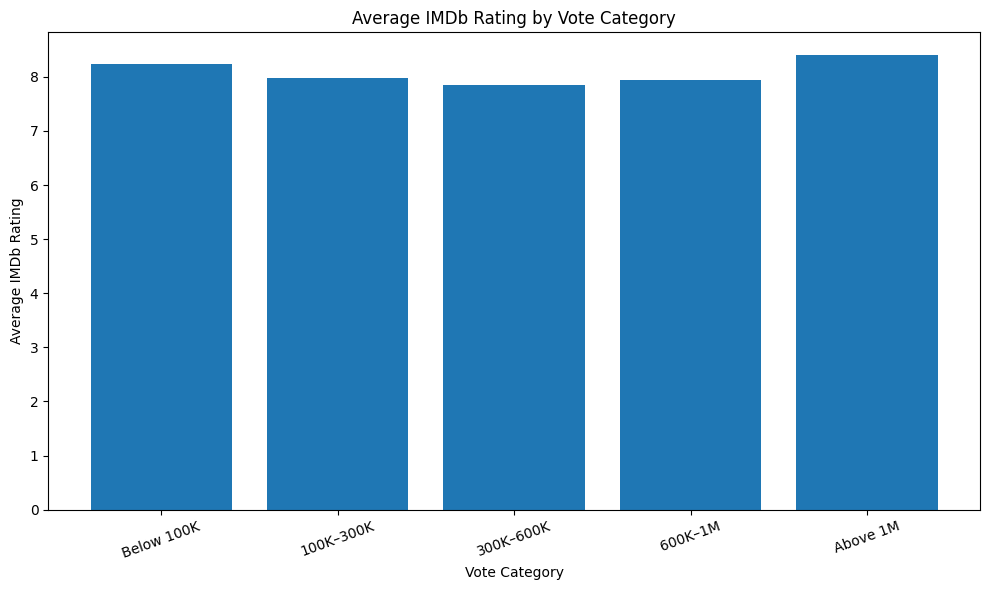

In [111]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    vote_analysis.index,
    vote_analysis['Avg_Rating']
)

plt.xlabel('Vote Category')
plt.ylabel('Average IMDb Rating')
plt.title('Average IMDb Rating by Vote Category')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating across different Vote Categories.

The **Above 1M** vote category has the highest average IMDb Rating at approximately **8.40**. The **Below 100K** category follows with an average rating of approximately **8.23**.

The **300K–600K** category has the lowest average IMDb Rating at approximately **7.85**.

The chart shows that the relationship between vote volume and IMDb Rating is not perfectly linear. Therefore, higher vote counts should not automatically be interpreted as the cause of higher ratings.

The differences should also be considered together with the number of movies in each category and other factors such as genre and decade.

**Decision:** Vote Category will be retained as an important segmentation variable for understanding audience engagement and its association with IMDb Rating.

In [112]:
director_track_record = (
    df.groupby('Director')
    .agg(
        Top700_Appearances=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Top700_Appearances', ascending=False)
)

director_track_record.head(20)

,Top700_Appearances,Avg_Rating,Avg_Votes
Director,,,
Steven Spielberg,12,8.066667,8.903054e+05
Martin Scorsese,11,8.063636,9.147289e+05
Quentin Tarantino,10,8.170000,1.169491e+06
Stanley Kubrick,10,8.120000,5.518008e+05
Christopher Nolan,10,8.460000,1.770058e+06
Alfred Hitchcock,9,8.133333,3.321999e+05
David Fincher,8,8.037500,1.141662e+06
Denis Villeneuve,7,8.071429,7.501567e+05
Hayao Miyazaki,7,8.142857,4.301341e+05


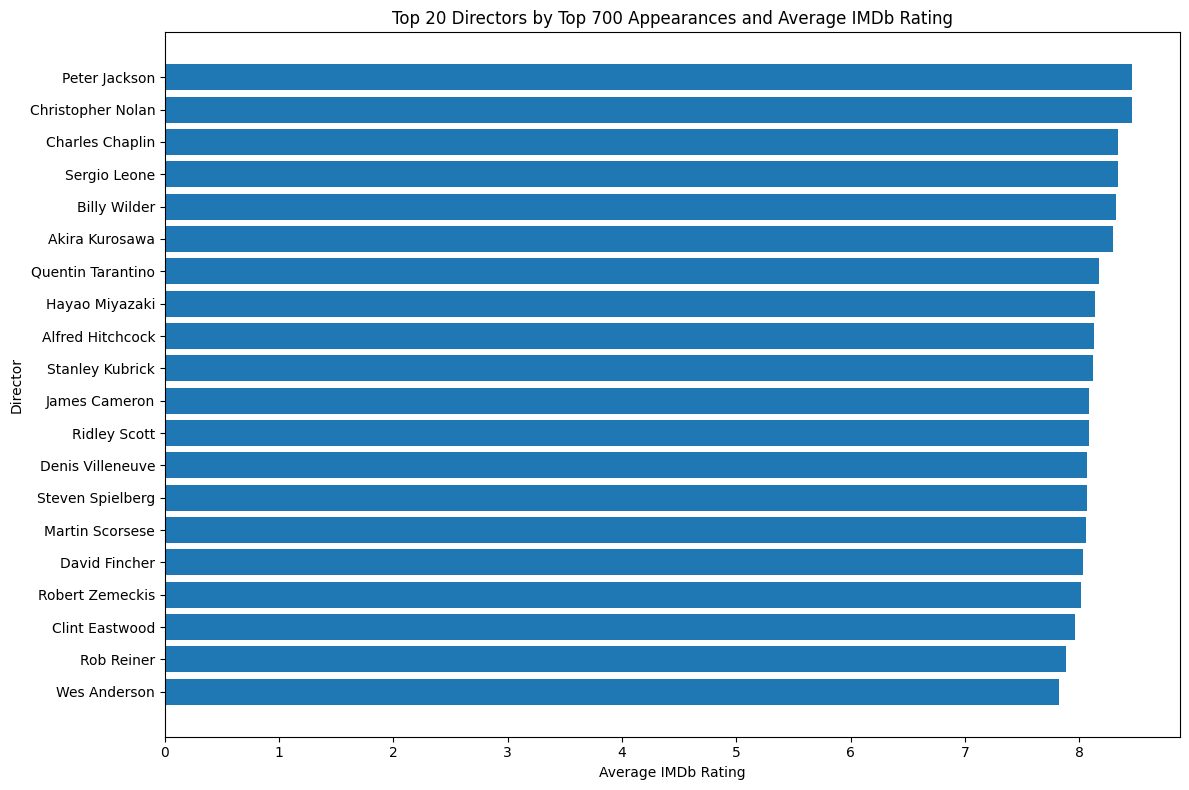

In [113]:
import matplotlib.pyplot as plt

top_directors = director_track_record.head(20).sort_values(
    'Avg_Rating',
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_directors.index,
    top_directors['Avg_Rating']
)

plt.xlabel('Average IMDb Rating')
plt.ylabel('Director')
plt.title('Top 20 Directors by Top 700 Appearances and Average IMDb Rating')

plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating of the 20 selected directors with multiple appearances in the IMDb Top 700 dataset.

Peter Jackson and Christopher Nolan have the highest average IMDb Rating in this selected group at approximately **8.46**. Charles Chaplin and Sergio Leone also show relatively high average ratings of approximately **8.34**.

The chart shows that average ratings vary across directors, but the differences are relatively small, with most directors having average ratings between approximately 7.8 and 8.5.

The number of Top 700 appearances also varies across the selected directors. Therefore, directors with fewer appearances should be interpreted more cautiously than directors with a larger number of observations.

**Decision:** Director track record will be evaluated using both Top 700 appearances and average IMDb Rating, while Average Votes will be used as an additional measure of audience engagement.

In [114]:
director_correlation = director_track_record[
    ['Top700_Appearances', 'Avg_Rating']
].corr()

director_correlation

,Top700_Appearances,Avg_Rating
Top700_Appearances,1.000000,0.063623
Avg_Rating,0.063623,1.000000


In [115]:
df['Main Actor(s)'].dropna().str.split('|').explode().value_counts().head(20)

,count
Main Actor(s),
Robert De Niro,16
Tom Hanks,14
Leonardo DiCaprio,14
Al Pacino,12
Christian Bale,11
Tom Cruise,11
Matt Damon,11
Brad Pitt,11
Emma Watson,10


### Interpretation

The actor frequency analysis shows which main actors appear most frequently among the movies in the IMDb Top 700 dataset.

Robert De Niro has the highest number of appearances with **16 movies**, followed by Tom Hanks and Leonardo DiCaprio with **14 appearances each**. Al Pacino appears in **12 movies**, while Christian Bale, Tom Cruise, Matt Damon, and Brad Pitt each appear in **11 movies**.

The frequency distribution shows that several actors have repeated appearances across highly ranked movies. However, the number of appearances alone does not indicate whether these movies have higher average IMDb Ratings.

Some actors also have relatively fewer observations, so appearance count should be considered before drawing conclusions from actor-level comparisons.

**Decision:** Actor frequency will be used as a supporting variable to examine whether repeated actor appearances are associated with average IMDb Rating. Actor-level rating analysis will be performed separately rather than interpreting frequency alone.

In [116]:
actor_df = df.copy()

actor_df['Main Actor(s)'] = actor_df['Main Actor(s)'].str.split('|')

actor_df = actor_df.explode('Main Actor(s)')

actor_analysis = (
    actor_df.groupby('Main Actor(s)')
    .agg(
        Top700_Appearances=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Top700_Appearances', ascending=False)
)

actor_analysis.head(20)

,Top700_Appearances,Avg_Rating,Avg_Votes
Main Actor(s),,,
Robert De Niro,16,8.106250,6.650936e+05
Leonardo DiCaprio,14,8.014286,1.189103e+06
Tom Hanks,14,8.028571,9.048663e+05
Al Pacino,12,8.083333,7.037994e+05
Tom Cruise,11,7.781818,5.236527e+05
Christian Bale,11,8.081818,1.225639e+06
Brad Pitt,11,7.990909,1.097571e+06
Matt Damon,11,8.127273,8.811609e+05
Robert Downey Jr.,10,8.050000,1.244160e+06


### Interpretation

The actor-level analysis compares Top 700 appearances, average IMDb Rating, and average Votes for the selected actors.

Among the selected actors, **Aamir Khan** has an average IMDb Rating of **8.23**, while **Harrison Ford** has an average rating of **8.18** and **Matt Damon** has **8.13**.

Robert De Niro has the highest number of Top 700 appearances with **16 movies** and an average rating of **8.11**.

Some actors with fewer appearances show relatively high average ratings, while actors with more appearances do not necessarily have the highest average ratings. For example, Robert De Niro has 16 appearances, whereas Aamir Khan has 8 appearances but a higher average rating.

Average Votes also vary substantially across actors. Leonardo DiCaprio, Christian Bale, and Robert Downey Jr. have relatively high average vote counts among the selected actors.

**Decision:** Actor track record will be treated as a supporting analytical dimension. Both appearance count and average IMDb Rating will be considered, while Average Votes will provide additional context about audience engagement.

In [117]:
actor_correlation = actor_analysis[
    ['Top700_Appearances', 'Avg_Rating']
].corr()

actor_correlation

,Top700_Appearances,Avg_Rating
Top700_Appearances,1.000000,-0.032011
Avg_Rating,-0.032011,1.000000


### Correlation Interpretation

The correlation between Top 700 Appearances and Average IMDb Rating is approximately **-0.032**.

This value is very close to zero, indicating that there is practically no linear relationship between the number of Top 700 appearances of an actor and their average IMDb Rating in this dataset.

In other words, actors with more appearances in the Top 700 do not necessarily have higher or lower average ratings based on this linear correlation.

The result suggests that repeated appearances alone are not sufficient to explain differences in average IMDb Rating.

**Decision:** Actor appearances will be treated as a supporting track-record metric rather than a direct indicator of higher IMDb Rating.

In [118]:
actor_correlation = actor_analysis[
    ['Top700_Appearances', 'Avg_Rating']
].corr()

actor_correlation

,Top700_Appearances,Avg_Rating
Top700_Appearances,1.000000,-0.032011
Avg_Rating,-0.032011,1.000000


### Correlation Interpretation

The correlation between Top 700 Appearances and Average IMDb Rating is approximately **-0.032**.

This value is very close to zero, indicating that there is practically no linear relationship between the number of Top 700 appearances of an actor and their average IMDb Rating in this dataset.

Therefore, actors with more appearances do not necessarily have higher or lower average IMDb Ratings based on this linear relationship.

**Decision:** Actor appearances will be treated as a supporting track-record metric rather than a direct indicator of higher IMDb Rating.

In [119]:
import pandas as pd

median_votes = df['Votes'].median()

df['Vote_Group'] = df['Votes'].apply(
    lambda x: 'High Votes' if x >= median_votes else 'Low Votes'
)

df.groupby('Vote_Group')['IMDb Rating'].agg(
    ['count', 'mean', 'std']
)

,count,mean,std
Vote_Group,,,
High Votes,350,8.020000,0.369542
Low Votes,350,7.980286,0.251949


### Interpretation

The comparison between High Votes and Low Votes groups shows that both groups have similar average IMDb Ratings.

- The **High Votes** group has an average IMDb Rating of **8.02**.
- The **Low Votes** group has an average IMDb Rating of approximately **7.98**.
- The difference between the two groups is approximately **0.04 rating points**.

Although the High Votes group has a slightly higher average rating, the difference is relatively small. Therefore, vote volume alone does not appear to create a large difference in average IMDb Rating between these two groups.

The High Votes group also shows greater variation in ratings, as indicated by its higher standard deviation.

**Decision:** Vote Group will be retained as a supporting segmentation variable, but the small difference in average ratings means that vote volume should not be interpreted as the sole explanation for differences in IMDb Rating.

In [120]:
from scipy.stats import ttest_ind

high_votes = df.loc[df['Vote_Group'] == 'High Votes', 'IMDb Rating']
low_votes = df.loc[df['Vote_Group'] == 'Low Votes', 'IMDb Rating']

t_stat, p_value = ttest_ind(
    high_votes,
    low_votes,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 1.6612015191447995
P-value: 0.09718196727916203


### Hypothesis Test Interpretation

The independent two-sample t-test was used to compare the average IMDb Ratings of the High Votes and Low Votes groups.

The test produced a **t-statistic of 1.661** and a **p-value of 0.0972**.

Since the p-value is greater than the 5% significance level (α = 0.05), the null hypothesis is **not rejected**.

This means that the observed difference in average IMDb Rating between the High Votes and Low Votes groups is **not statistically significant at the 5% level** in this dataset.

Although the High Votes group has a slightly higher observed average rating, the statistical test does not provide sufficient evidence to conclude that the two groups have different population mean ratings.

**Decision:** Vote volume will be retained as a supporting variable, but the High Votes vs Low Votes comparison will not be treated as statistically significant at the 5% level.

In [121]:
import numpy as np

pooled_std = np.sqrt(
    (
        (len(high_votes) - 1) * high_votes.std()**2 +
        (len(low_votes) - 1) * low_votes.std()**2
    )
    / (len(high_votes) + len(low_votes) - 2)
)

cohens_d = (high_votes.mean() - low_votes.mean()) / pooled_std

print("Cohen's d:", cohens_d)

Cohen's d: 0.1255750313491383


### Effect Size Interpretation

To understand the practical magnitude of the difference between the High Votes and Low Votes groups, Cohen's d was calculated.

The Cohen's d value is **0.126**, which indicates a **very small effect size**.

This means that the difference in average IMDb Rating between the two vote groups is small in practical terms, consistent with the earlier hypothesis test where the difference was not statistically significant at the 5% level.

**Decision:** The results suggest that dividing movies into High Votes and Low Votes groups does not produce a meaningful difference in average IMDb Rating in this dataset. Therefore, Vote Group will be treated as a supporting variable rather than a strong differentiating factor.

In [122]:
from scipy.stats import pearsonr

correlation, p_value = pearsonr(
    df['Runtime (mins)'],
    df['IMDb Rating']
)

print("Pearson Correlation:", correlation)
print("P-value:", p_value)


Pearson Correlation: 0.23872716916709022
P-value: 1.5787560961321961e-10


### Statistical Significance Interpretation

The Pearson correlation test was used to evaluate the relationship between Runtime and IMDb Rating.

The analysis produced a **Pearson correlation coefficient of 0.239** and a **p-value of approximately 1.58 × 10⁻¹⁰**.

Since the p-value is substantially below the 5% significance level (α = 0.05), the null hypothesis of no linear relationship is rejected.

This indicates that there is a **statistically significant positive linear association** between Runtime and IMDb Rating in this dataset.

However, the correlation coefficient of 0.239 indicates that the relationship is **weak in strength**. Therefore, statistical significance should not be interpreted as a strong relationship or as evidence that longer runtime causes higher IMDb Ratings.

**Decision:** Runtime will be retained as a statistically significant supporting variable, but its weak correlation means it should be analysed alongside other factors such as Votes, Genre, Decade, Director, and Country.

In [123]:
df['Runtime_Category'] = pd.cut(
    df['Runtime (mins)'],
    bins=[0, 90, 120, 150, float('inf')],
    labels=[
        'Below 90 mins',
        '90–120 mins',
        '120–150 mins',
        'Above 150 mins'
    ]
)

runtime_analysis = (
    df.groupby('Runtime_Category', observed=True)
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
)

runtime_analysis

,Movie_Count,Avg_Rating,Avg_Votes
Runtime_Category,,,
Below 90 mins,43,7.976744,335614.372093
90–120 mins,275,7.938545,488253.854545
120–150 mins,249,7.998394,574118.056225
Above 150 mins,133,8.138346,612868.518797


### Chart Interpretation

The chart compares the average IMDb Rating across four Runtime Categories.

Movies with a runtime of **Above 150 minutes** have the highest average IMDb Rating at approximately **8.14**. The 120–150 minute category follows with an average rating of approximately **8.00**.

The **90–120 minute** category has the lowest average rating at approximately **7.94**, while movies below 90 minutes have an average rating of approximately **7.98**.

The results show that longer movies, particularly those above 150 minutes, have a higher observed average IMDb Rating in this dataset. This pattern is consistent with the earlier Runtime analysis, which showed a weak positive correlation between Runtime and IMDb Rating.

However, differences in average rating do not establish that longer runtime causes higher ratings. Other factors such as genre, decade, director, and votes may also contribute to these differences.

**Decision:** Runtime Category will be retained as an important segmentation variable. The Above 150 minutes group will receive further attention because it shows the highest observed average rating, while the result will be interpreted alongside other movie characteristics.

## 3.5 Genre Performance: Rating and Audience Engagement

Genre analysis showed that average IMDb Ratings vary across genres. However, rating alone does not provide a complete picture of a movie's performance.

To understand genre performance more deeply, I will compare:
- Average IMDb Rating
- Average Votes
- Number of movie appearances

This will help identify whether highly rated genres also show stronger audience engagement.

In [124]:
genre_df = df.copy()

genre_df['Genre(s)'] = genre_df['Genre(s)'].apply(
    lambda x: x if isinstance(x, list) else str(x).split('|')
)

genre_df = genre_df.explode('Genre(s)')

genre_df['Genre(s)'] = genre_df['Genre(s)'].str.strip()

genre_df[['Title', 'Genre(s)']].head(10)

,Title,Genre(s)
0,The Shawshank Redemption,Drama
1,The Godfather,Crime
1,The Godfather,Drama
2,The Dark Knight,Crime
2,The Dark Knight,Thriller
3,The Lord of the Rings: The Return of the King,Adventure
3,The Lord of the Rings: The Return of the King,Drama
3,The Lord of the Rings: The Return of the King,Fantasy
4,Schindler's List,Biography
4,Schindler's List,Drama


### Chart Interpretation

The chart compares genres using three dimensions: **Average IMDb Rating, Average Votes, and Movie Count**. This provides a broader view of genre performance instead of relying on rating alone.

- **Drama** has the largest representation in the dataset and also shows a strong average vote count, indicating substantial audience engagement across a large number of movies.
- **Action and Adventure** also have relatively high average vote counts, showing strong audience engagement within these genres.
- **Crime** has a relatively high number of movie appearances and maintains an average rating close to the overall dataset level.
- **Comedy and Thriller** have substantial representation and moderate average ratings and vote counts, making them important genres for comparison.
- **Fantasy and Sci-Fi** show relatively high audience engagement through votes, although their average ratings are slightly below the highest-rated genres.
- **Biography and Horror** have fewer movie appearances compared with the major genres, so their averages should be interpreted with greater caution.

An important observation is that **higher audience engagement does not always correspond to a higher average IMDb Rating**. For example, some genres receive a large number of votes while having only moderate average ratings.

The Movie Count is also important because genres with fewer observations can show higher or lower averages that may be less stable than those of highly represented genres.

**Decision:** Genre will be retained as an important segmentation variable for the final analysis. Average IMDb Rating will be evaluated together with Average Votes and Movie Count so that both **audience engagement and rating performance** are considered. Small-sample genres will not be used to make strong general conclusions.

In [125]:
genre_performance = (
    genre_df.groupby('Genre(s)')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_values('Avg_Rating', ascending=False)
)

# Keep genres with at least 10 movie appearances
genre_performance_filtered = genre_performance[
    genre_performance['Movie_Count'] >= 10
]

genre_performance_filtered


,Movie_Count,Avg_Rating,Avg_Votes
Genre(s),,,
War,32,8.175000,473960.281250
Western,13,8.123077,490463.384615
Biography,78,8.037179,426798.153846
Drama,473,8.028330,480990.642706
Animation,63,8.017460,500848.047619
Crime,156,8.014744,549694.294872
Music,16,8.006250,392191.125000
Sport,16,7.993750,343668.000000
Sci-Fi,62,7.991935,878560.419355


In [126]:
print("Genre rows:", genre_df.shape[0])

print("\nTop genre counts:")
print(genre_df['Genre(s)'].value_counts().head(15))

print("\nGenre performance:")
print(genre_performance.head(15))

Genre rows: 1823

Top genre counts:
Genre(s)
Drama        473
Adventure    176
Action       160
Crime        156
Comedy       149
Thriller     106
Mystery       80
Biography     78
Romance       72
Animation     63
Sci-Fi        62
Fantasy       57
Family        36
War           32
Horror        28
Name: count, dtype: int64

Genre performance:
             Movie_Count  Avg_Rating      Avg_Votes
Genre(s)                                           
Documentary            8    8.237500   84884.125000
War                   32    8.175000  473960.281250
Musical                7    8.128571  154630.714286
Western               13    8.123077  490463.384615
Film-Noir              8    8.037500  162590.000000
Biography             78    8.037179  426798.153846
Drama                473    8.028330  480990.642706
Animation             63    8.017460  500848.047619
Crime                156    8.014744  549694.294872
Music                 16    8.006250  392191.125000
Sport                 16    7.

In [127]:
genre_performance_filtered = (
    genre_performance[
        genre_performance['Movie_Count'] >= 10
    ]
    .sort_values('Avg_Rating', ascending=False)
)

genre_performance_filtered

,Movie_Count,Avg_Rating,Avg_Votes
Genre(s),,,
War,32,8.175000,473960.281250
Western,13,8.123077,490463.384615
Biography,78,8.037179,426798.153846
Drama,473,8.028330,480990.642706
Animation,63,8.017460,500848.047619
Crime,156,8.014744,549694.294872
Music,16,8.006250,392191.125000
Sport,16,7.993750,343668.000000
Sci-Fi,62,7.991935,878560.419355


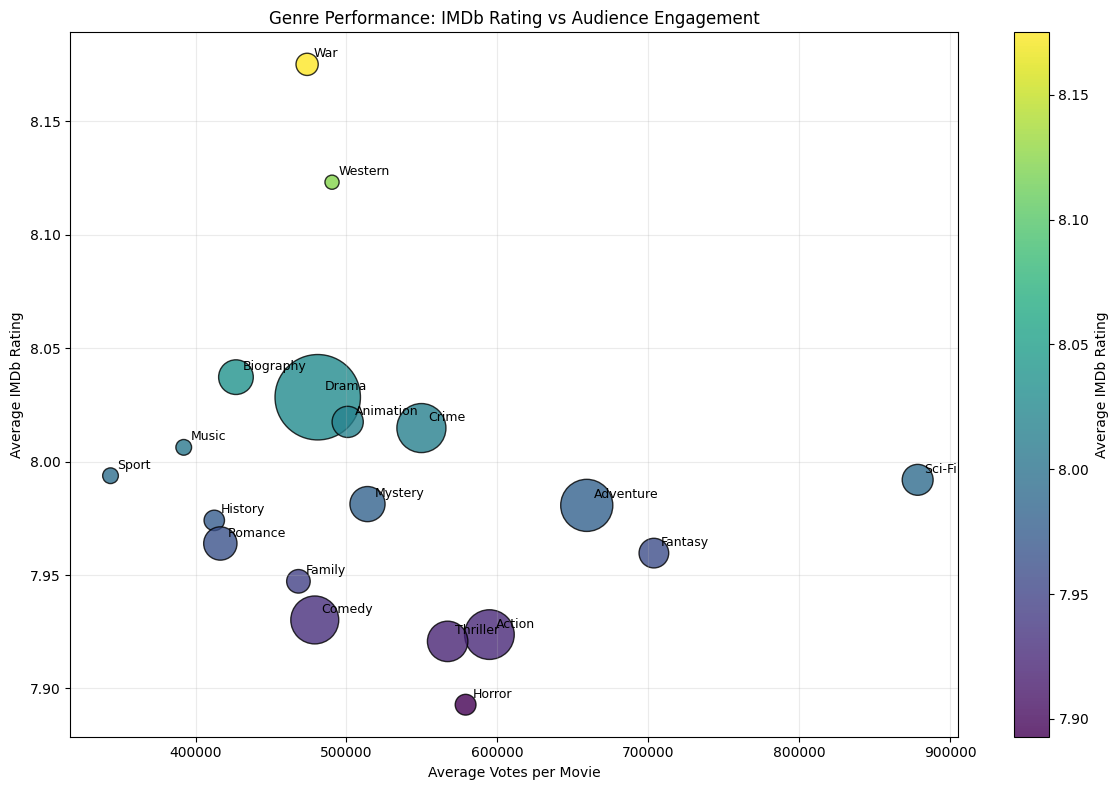

In [128]:
import matplotlib.pyplot as plt

genre_chart = genre_performance[
    genre_performance['Movie_Count'] >= 10
].copy()

plt.figure(figsize=(12, 8))

plt.scatter(
    genre_chart['Avg_Votes'],
    genre_chart['Avg_Rating'],
    s=genre_chart['Movie_Count'] * 8,
    c=genre_chart['Avg_Rating'],
    cmap='viridis',
    alpha=0.8,
    edgecolors='black'
)

for genre, row in genre_chart.iterrows():
    plt.annotate(
        genre,
        (row['Avg_Votes'], row['Avg_Rating']),
        xytext=(5, 5),
        textcoords='offset points',
        fontsize=9
    )

plt.xlabel('Average Votes per Movie')
plt.ylabel('Average IMDb Rating')
plt.title('Genre Performance: IMDb Rating vs Audience Engagement')

plt.colorbar(label='Average IMDb Rating')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Genre Rating vs Audience Engagement

The previous genre analysis showed that average IMDb Rating varies across genres, but rating alone does not explain how strongly audiences engage with movies in each genre.

To examine this further, I will compare **Average IMDb Rating** with **Average Votes per Movie** at the genre level.

This visualization uses:

- **X-axis:** Average Votes per Movie, representing audience engagement
- **Y-axis:** Average IMDb Rating, representing rating performance
- **Bubble size:** Number of movie appearances for each genre
- **Color:** Average IMDb Rating

Genres with at least 10 movie appearances are included to reduce the influence of very small samples.

This analysis will help determine whether genres with higher audience engagement also tend to have higher average IMDb Ratings, or whether rating performance and popularity follow different patterns.

### Genre-Level Relationship Between Rating and Audience Engagement

The previous visualization compared Average IMDb Rating with Average Votes across genres.

To quantify this relationship, I will calculate the **Pearson correlation** between genre-level Average IMDb Rating and Average Votes.

This will help measure whether genres with higher average ratings also tend to receive more audience engagement.

A positive correlation would indicate that higher-rated genres tend to have higher average vote counts, while a value close to zero would indicate a weak linear relationship.

This analysis measures association only and does not imply that higher ratings cause more audience engagement.

In [129]:
genre_corr = genre_performance[
    genre_performance['Movie_Count'] >= 10
][['Avg_Rating', 'Avg_Votes']].corr()

genre_corr

,Avg_Rating,Avg_Votes
Avg_Rating,1.000000,-0.209121
Avg_Votes,-0.209121,1.000000


### Correlation Interpretation

The Pearson correlation between genre-level Average IMDb Rating and Average Votes is **-0.209**.

This indicates a **weak negative linear relationship** between the two variables in the selected genres.

In this dataset, genres with higher average IMDb Ratings do not necessarily receive higher average audience engagement. In fact, the weak negative direction suggests that genres with higher average ratings tend to have slightly lower average vote counts at the genre level.

However, the relationship is weak, so Average Votes cannot be used as a strong indicator of genre-level IMDb Rating.

This finding also shows why rating and popularity should be analysed as separate dimensions rather than assuming that highly rated genres are automatically the most popular.

**Decision:** Genre performance will be evaluated using both **Average IMDb Rating** and **Average Votes**, rather than using audience engagement as a proxy for rating quality.

## 3.6 Multivariate Analysis: Factors Associated with IMDb Rating

The earlier correlation analysis examined Votes and Runtime separately in relation to IMDb Rating.

However, a movie's rating may be associated with multiple characteristics at the same time. Therefore, I will use a multiple linear regression model to examine the relationship of **Votes and Runtime with IMDb Rating simultaneously**.

Because the Votes variable is highly right-skewed, I will use a logarithmic transformation of Votes before modelling.

The model will help answer:

- How is IMDb Rating associated with audience vote volume when Runtime is considered simultaneously?
- How is IMDb Rating associated with Runtime when Vote volume is considered simultaneously?
- How much variation in IMDb Rating is explained collectively by these variables?

This analysis identifies statistical associations and does not establish causal relationships.

In [130]:
import numpy as np
import statsmodels.api as sm

regression_df = df[
    ['IMDb Rating', 'Votes', 'Runtime (mins)']
].copy()

# Log transformation to reduce the effect of extremely high vote counts
regression_df['Log_Votes'] = np.log1p(regression_df['Votes'])

X = regression_df[['Log_Votes', 'Runtime (mins)']]
X = sm.add_constant(X)

y = regression_df['IMDb Rating']

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            IMDb Rating   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     28.43
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           1.36e-12
Time:                        05:50:20   Log-Likelihood:                -160.36
No. Observations:                 700   AIC:                             326.7
Df Residuals:                     697   BIC:                             340.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.0316      0.179     39.

### Regression Model Interpretation

The multiple linear regression model was fitted using **Log_Votes** and **Runtime (mins)** as explanatory variables and **IMDb Rating** as the dependent variable.

The model has an **R-squared of 0.075**, meaning that Log_Votes and Runtime together explain approximately **7.5% of the variation in IMDb Rating** in this dataset.

The overall regression model is statistically significant, with an F-statistic p-value of approximately **1.36 × 10⁻¹²**.

Both explanatory variables are statistically significant at the 5% significance level:

- **Log_Votes:** coefficient = **0.0505**, p < 0.001. Holding Runtime constant, higher vote volume is positively associated with IMDb Rating.
- **Runtime:** coefficient = **0.0025**, p < 0.001. Holding Log_Votes constant, longer Runtime is positively associated with IMDb Rating.

The relatively low R-squared indicates that Votes and Runtime explain only a small portion of the variation in IMDb Rating. Therefore, other factors such as Genre, Decade, Director, Country, and other movie characteristics may also contribute to differences in ratings.

The model identifies statistical associations and should not be interpreted as evidence of causation.

**Decision:** Votes and Runtime will be retained as statistically significant supporting variables, but the low explanatory power of the model indicates that IMDb Rating is influenced by multiple factors. This supports further analysis using categorical variables such as Genre, Decade, Director, and Country.

## 3.7 Regression Diagnostic: Residual Analysis

After fitting the multiple linear regression model, it is important to examine whether the model's residuals show any systematic pattern.

Residuals are the differences between the actual IMDb Rating and the rating predicted by the regression model.

I will plot **Residuals vs Fitted Values** to check whether the residuals are reasonably scattered around zero.

A random spread of residuals would indicate that the model does not show an obvious systematic pattern, while a visible pattern or changing spread may indicate that the model does not fully capture the relationship in the data.

This diagnostic is used to assess model behaviour; it does not determine whether the relationships identified by the model are causal.

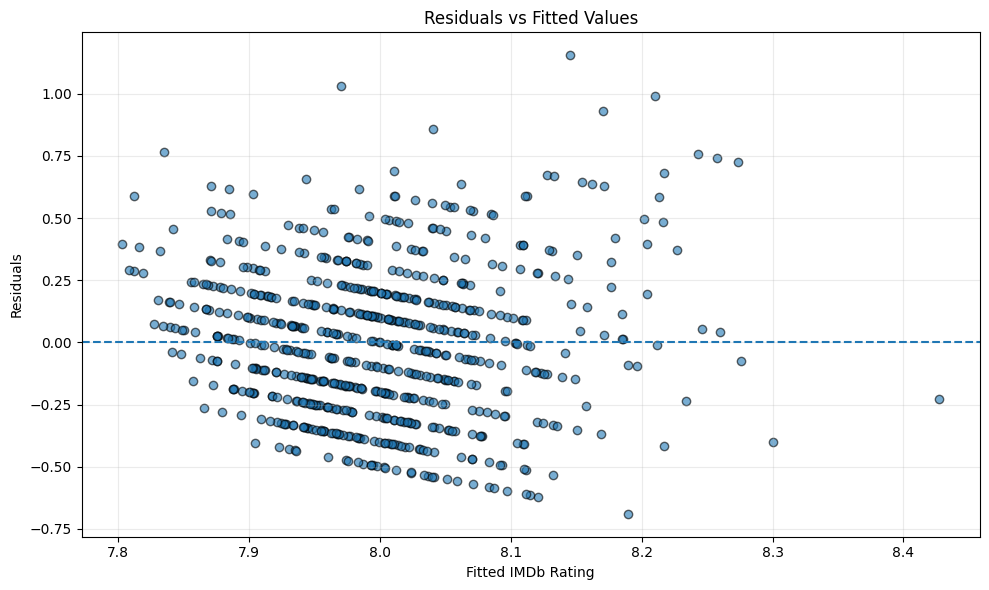

In [131]:
import matplotlib.pyplot as plt

fitted_values = model.fittedvalues
residuals = model.resid

plt.figure(figsize=(10, 6))

plt.scatter(
    fitted_values,
    residuals,
    alpha=0.6,
    edgecolors='black'
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel('Fitted IMDb Rating')
plt.ylabel('Residuals')
plt.title('Residuals vs Fitted Values')
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Residual Diagnostic Interpretation

The Residuals vs Fitted Values plot shows that the residuals are distributed around the zero reference line without a clear curved pattern.

However, the spread of residuals becomes somewhat wider at higher fitted IMDb Ratings. This suggests that the model may not capture all sources of variation equally well across the rating range.

The horizontal bands visible in the plot are expected because IMDb Ratings in the dataset are recorded in discrete increments, such as 7.8, 7.9, 8.0, and 8.1.

Overall, the diagnostic does not show an obvious systematic curved pattern, but the increasing spread indicates that the regression model has limitations in explaining the variation in IMDb Rating.

**Decision:** The regression model will be used as a supporting analytical model rather than a highly predictive model. The low R-squared and residual pattern reinforce the need to consider additional factors such as Genre, Decade, Director, and Country.

## 3.8 Regression Diagnostic: Breusch-Pagan Test

The residual plot suggested that the spread of residuals may change across fitted IMDb Ratings.

To formally test this, I will use the **Breusch-Pagan test** for heteroscedasticity.

The null hypothesis (H₀) is that the residual variance is constant.

The alternative hypothesis (H₁) is that the residual variance is not constant.

A p-value below 0.05 would provide statistical evidence of heteroscedasticity.

This test helps assess the reliability of the standard errors used in the regression model.

In [132]:
from statsmodels.stats.diagnostic import het_breuschpagan

bp_test = het_breuschpagan(
    model.resid,
    model.model.exog
)

bp_labels = [
    'LM Statistic',
    'LM-Test p-value',
    'F-Statistic',
    'F-Test p-value'
]

bp_results = dict(zip(bp_labels, bp_test))

bp_results

{'LM Statistic': np.float64(57.52956049584147),
 'LM-Test p-value': np.float64(3.21821211319547e-13),
 'F-Statistic': np.float64(31.20618568579448),
 'F-Test p-value': np.float64(1.0475045752119912e-13)}

### Breusch-Pagan Test Interpretation

The Breusch-Pagan test was used to formally assess whether the variance of the regression residuals is constant.

The test produced:

- LM Statistic = **57.53**
- LM-Test p-value = **3.22 × 10⁻¹³**
- F-Statistic = **31.21**
- F-Test p-value = **1.05 × 10⁻¹³**

Since the p-value is substantially below the 5% significance level (α = 0.05), the null hypothesis of constant residual variance is rejected.

This provides statistical evidence of **heteroscedasticity** in the regression model. Therefore, the conventional OLS standard errors may not be fully reliable for statistical inference.

**Decision:** Because heteroscedasticity is present, I will use heteroscedasticity-robust (HC3) standard errors to reassess the statistical significance of the regression coefficients.

In [133]:
robust_model = model.get_robustcov_results(cov_type='HC3')

print(robust_model.summary())

                            OLS Regression Results                            
Dep. Variable:            IMDb Rating   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     20.72
Date:                Sat, 26 Sep 2026   Prob (F-statistic):           1.82e-09
Time:                        05:50:20   Log-Likelihood:                -160.36
No. Observations:                 700   AIC:                             326.7
Df Residuals:                     697   BIC:                             340.4
Df Model:                           2                                         
Covariance Type:                  HC3                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              7.0316      0.222     31.

### Robust Regression Results

The Breusch-Pagan test indicated the presence of heteroscedasticity in the regression residuals.

To account for this issue, I will use **HC3 heteroscedasticity-robust standard errors**. The regression coefficients remain the same, but the robust standard errors and p-values provide more reliable statistical inference when residual variance is not constant.

The robust results will be compared with the original OLS results before drawing the final conclusion.

## 3.9 Era-wise Rating Stability

The decade analysis showed that the representation and average IMDb Rating of Top 700 movies vary across different periods.

To examine this pattern at a broader level, I will group movies into larger historical eras rather than individual decades.

This reduces the effect of very small decade-level samples and makes it easier to compare the rating profile of different periods.

The eras will be defined as:

- **Pre-1980**
- **1980–1999**
- **2000–2009**
- **2010–2019**
- **2020 onwards**

For each era, I will compare:
- Number of movies
- Average IMDb Rating
- Average Votes

This analysis will help identify whether the characteristics of highly rated movies have remained consistent across different periods.

In [134]:
df_era = df.copy()

df_era['Era'] = pd.cut(
    df_era['Year'],
    bins=[0, 1979, 1999, 2009, 2019, 2026],
    labels=[
        'Pre-1980',
        '1980–1999',
        '2000–2009',
        '2010–2019',
        '2020 onwards'
    ]
)

era_analysis = (
    df_era.groupby('Era', observed=True)
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
)

era_analysis

,Movie_Count,Avg_Rating,Avg_Votes
Era,,,
Pre-1980,121,8.137190,325758.082645
1980–1999,156,8.038462,614794.250000
2000–2009,177,7.924294,608729.333333
2010–2019,181,7.929834,604678.154696
2020 onwards,65,8.055385,317717.969231


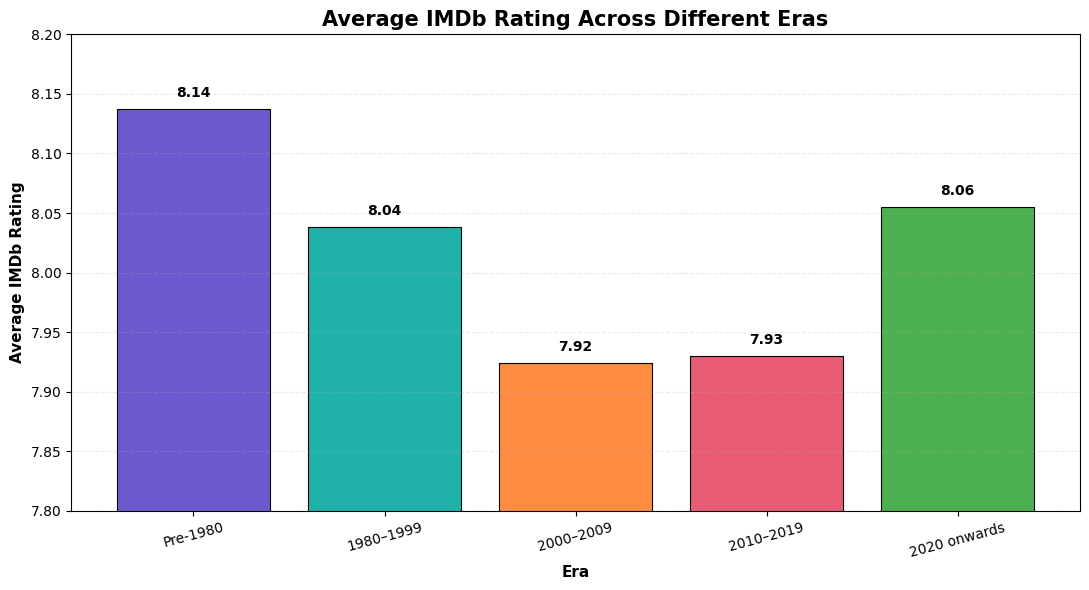

In [135]:
import matplotlib.pyplot as plt

era_chart = era_analysis.reset_index()

plt.figure(figsize=(11, 6))

bars = plt.bar(
    era_chart['Era'],
    era_chart['Avg_Rating'],
    color=['#6A5ACD', '#20B2AA', '#FF8C42', '#E85D75', '#4CAF50'],
    edgecolor='black',
    linewidth=0.8
)

# Add rating values on top of bars
for bar, value in zip(bars, era_chart['Avg_Rating']):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f'{value:.2f}',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.xlabel('Era', fontsize=11, fontweight='bold')
plt.ylabel('Average IMDb Rating', fontsize=11, fontweight='bold')
plt.title(
    'Average IMDb Rating Across Different Eras',
    fontsize=15,
    fontweight='bold'
)

plt.ylim(7.8, 8.2)
plt.grid(axis='y', linestyle='--', alpha=0.25)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Chart Interpretation

The chart compares the average IMDb Rating across five historical eras.

The **Pre-1980** era has the highest average IMDb Rating at approximately **8.14**, while the **2000–2009** era has the lowest average at approximately **7.92**.

The **2010–2019** era has a very similar average rating of approximately **7.93**, while the **2020 onwards** era shows an increase to approximately **8.06**.

The number of movies represented in each era also varies. The 2000s and 2010s contain the largest number of movies in the dataset, while the 2020 onwards group contains fewer observations.

Overall, the chart suggests that average IMDb Rating varies across eras, but these differences should be interpreted together with the number of movies represented in each period.

**Decision:** Era will be retained as an important segmentation variable for understanding how the rating profile of highly ranked movies changes across time.

## 3.10 Era-wise Audience Engagement vs IMDb Rating

The previous analysis compared the average IMDb Rating across different eras.

However, rating alone does not show whether movies from an era also received strong audience engagement. Therefore, I will compare **Average IMDb Rating** with **Average Votes per Movie** across eras.

This analysis will help identify whether highly rated eras also tend to have higher audience engagement.

The comparison will consider:
- Average IMDb Rating
- Average Votes per Movie
- Number of movies in each era

This provides a broader view of how rating performance and audience engagement have varied over time.

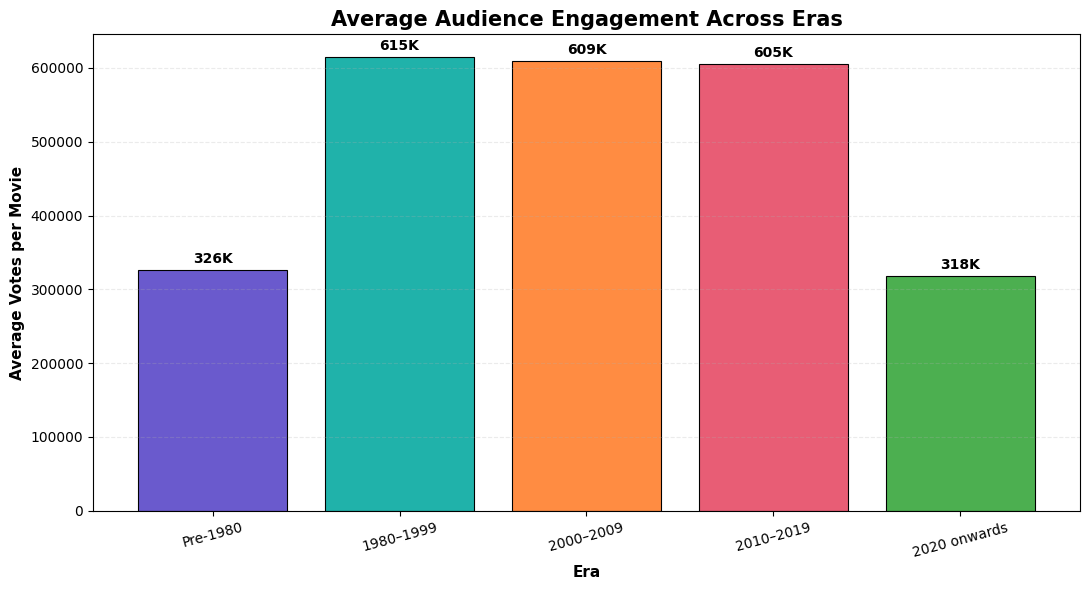

In [136]:
import matplotlib.pyplot as plt

era_chart = era_analysis.reset_index()

plt.figure(figsize=(11, 6))

bars = plt.bar(
    era_chart['Era'],
    era_chart['Avg_Votes'],
    color=['#6A5ACD', '#20B2AA', '#FF8C42', '#E85D75', '#4CAF50'],
    edgecolor='black',
    linewidth=0.8
)

for bar, value in zip(bars, era_chart['Avg_Votes']):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 10000,
        f'{value/1000:.0f}K',
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

plt.xlabel('Era', fontsize=11, fontweight='bold')
plt.ylabel('Average Votes per Movie', fontsize=11, fontweight='bold')
plt.title(
    'Average Audience Engagement Across Eras',
    fontsize=15,
    fontweight='bold'
)

plt.grid(axis='y', linestyle='--', alpha=0.25)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 3.11 IMDb Rank and Rating Relationship

The IMDb Top 700 dataset contains a Rank assigned to each movie.

Since the business objective is to understand what characteristics are associated with highly ranked movies, it is important to examine whether IMDb Rank is strongly related to IMDb Rating.

I will compare:
- IMDb Rank
- IMDb Rating

A scatter plot will be used to visualize the relationship, followed by a correlation analysis.

This will help establish how strongly the ranking position is associated with the movie's average IMDb Rating.

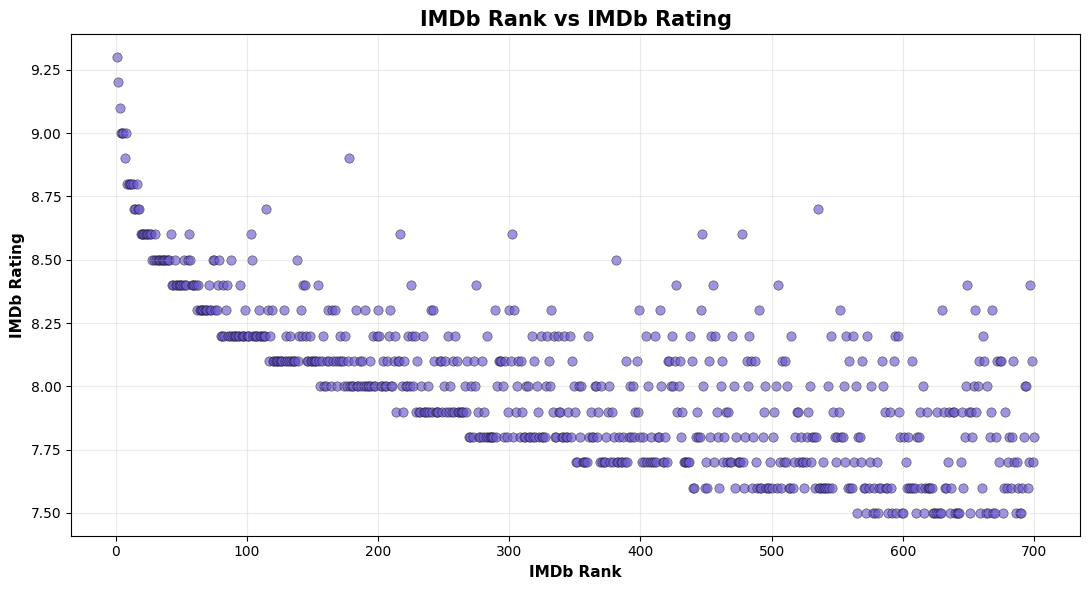

In [137]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.scatter(
    df['Rank'],
    df['IMDb Rating'],
    s=45,
    alpha=0.65,
    color='#6A5ACD',
    edgecolors='black',
    linewidth=0.4
)

plt.xlabel('IMDb Rank', fontsize=11, fontweight='bold')
plt.ylabel('IMDb Rating', fontsize=11, fontweight='bold')
plt.title(
    'IMDb Rank vs IMDb Rating',
    fontsize=15,
    fontweight='bold'
)

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3.12 IMDb Rating Distribution

The previous analyses compared IMDb Rating across genres, eras, countries, directors, and other movie characteristics.

Before drawing broader conclusions, it is important to understand how IMDb Ratings are distributed across the entire Top 700 dataset.

I will examine the frequency of different IMDb Rating values to identify:

- Where most Top 700 movies are concentrated
- Whether very high ratings are relatively rare
- How much variation exists in the core IMDb Rating metric

This provides a baseline for interpreting the group-level rating comparisons performed earlier.

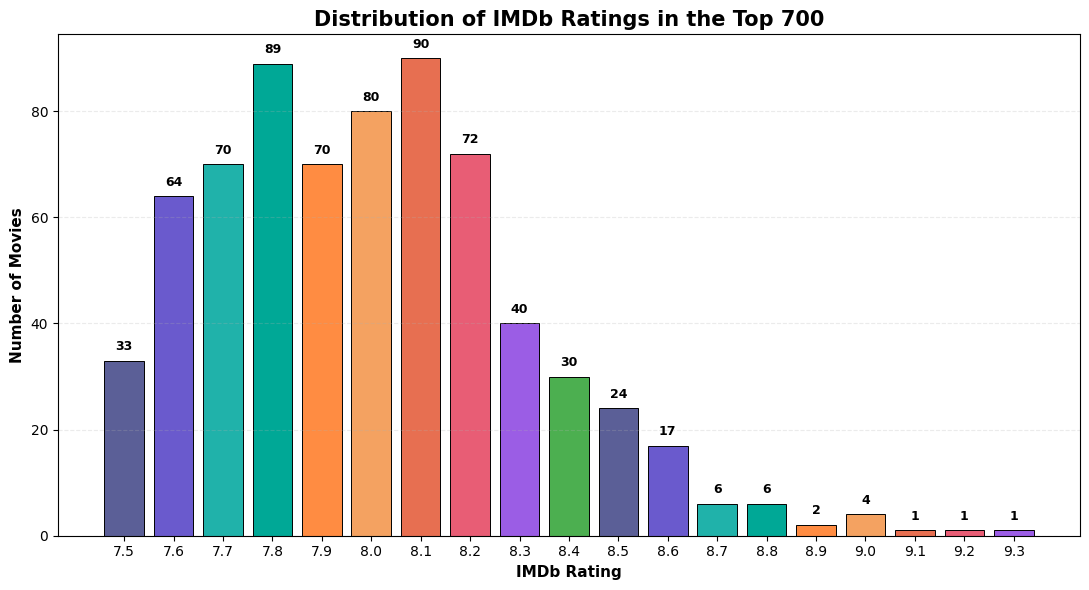

In [138]:
import matplotlib.pyplot as plt

rating_counts = df['IMDb Rating'].value_counts().sort_index()

plt.figure(figsize=(11, 6))

bars = plt.bar(
    rating_counts.index.astype(str),
    rating_counts.values,
    color=[
        '#5B5F97', '#6A5ACD', '#20B2AA', '#00A896',
        '#FF8C42', '#F4A261', '#E76F51', '#E85D75',
        '#9B5DE5', '#4CAF50'
    ][:len(rating_counts)],
    edgecolor='black',
    linewidth=0.7
)

for bar, value in zip(bars, rating_counts.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 2,
        str(value),
        ha='center',
        fontsize=9,
        fontweight='bold'
    )

plt.xlabel('IMDb Rating', fontsize=11, fontweight='bold')
plt.ylabel('Number of Movies', fontsize=11, fontweight='bold')
plt.title(
    'Distribution of IMDb Ratings in the Top 700',
    fontsize=15,
    fontweight='bold'
)

plt.grid(axis='y', linestyle='--', alpha=0.25)
plt.tight_layout()
plt.show()

## 3.13 Genre Diversity and IMDb Rating

Movies in the dataset can belong to one or more genres.

A movie with multiple genres may combine different storytelling styles, such as Drama + Crime or Adventure + Drama + Fantasy.

To investigate whether genre diversity is associated with IMDb Rating, I will calculate the number of genres assigned to each movie and compare this with its IMDb Rating.

This analysis will help determine whether movies with multiple genre classifications tend to have different rating profiles from movies with a single genre classification.

The analysis measures association and does not imply that having more genres causes a higher or lower rating.

In [139]:
genre_diversity_df = df.copy()

genre_diversity_df['Genre_Count'] = genre_diversity_df['Genre(s)'].apply(
    lambda x: len(x) if isinstance(x, list) else len(str(x).split('|'))
)

genre_diversity_analysis = (
    genre_diversity_df
    .groupby('Genre_Count')
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Avg_Votes=('Votes', 'mean')
    )
    .sort_index()
)

genre_diversity_analysis

,Movie_Count,Avg_Rating,Avg_Votes
Genre_Count,,,
1,53,8.047170,495542.358491
2,171,8.071345,584367.052632
3,476,7.969328,518860.558824


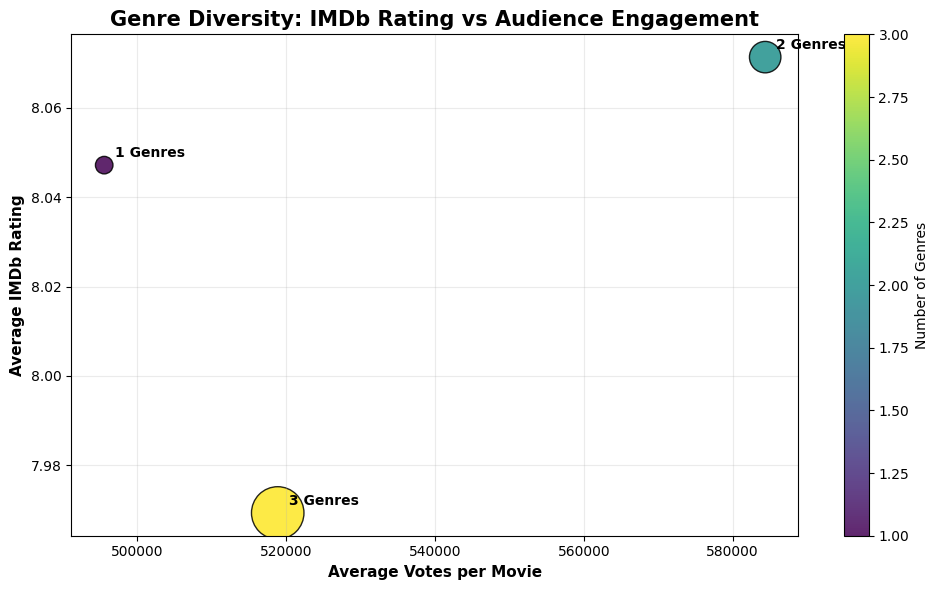

In [140]:
import matplotlib.pyplot as plt

genre_diversity_chart = genre_diversity_analysis.reset_index()

plt.figure(figsize=(10, 6))

plt.scatter(
    genre_diversity_chart['Avg_Votes'],
    genre_diversity_chart['Avg_Rating'],
    s=genre_diversity_chart['Movie_Count'] * 3,
    c=genre_diversity_chart['Genre_Count'],
    cmap='viridis',
    alpha=0.85,
    edgecolors='black',
    linewidth=1
)

# Add labels for each point
for _, row in genre_diversity_chart.iterrows():
    plt.annotate(
        f"{int(row['Genre_Count'])} Genres",
        (row['Avg_Votes'], row['Avg_Rating']),
        xytext=(8, 6),
        textcoords='offset points',
        fontsize=10,
        fontweight='bold'
    )

plt.xlabel('Average Votes per Movie', fontsize=11, fontweight='bold')
plt.ylabel('Average IMDb Rating', fontsize=11, fontweight='bold')

plt.title(
    'Genre Diversity: IMDb Rating vs Audience Engagement',
    fontsize=15,
    fontweight='bold'
)

plt.grid(alpha=0.25)
plt.colorbar(label='Number of Genres')
plt.tight_layout()
plt.show()

## 3.14 Relationship Between IMDb Rank and IMDb Rating

The IMDb Rank represents the position of a movie within the Top 700 list, while IMDb Rating represents its average user rating.

To understand whether higher-ranked movies tend to have higher IMDb Ratings, I will measure the statistical relationship between Rank and IMDb Rating.

Because Rank is an ordered position, a negative relationship would indicate that movies appearing closer to Rank 1 tend to have higher ratings.

I will calculate the Pearson correlation as an initial measure of linear association.

This analysis measures association and does not imply that rank causes a change in IMDb Rating.

In [141]:
rank_rating_corr = df[['Rank', 'IMDb Rating']].corr()

rank_rating_corr

,Rank,IMDb Rating
Rank,1.000000,-0.709046
IMDb Rating,-0.709046,1.000000


### Correlation Interpretation

The Pearson correlation coefficient between **IMDb Rank** and **IMDb Rating** is **-0.709**.

This indicates a **strong negative relationship** between Rank and IMDb Rating.

Because a lower numerical rank represents a higher position in the Top 700 list, the negative correlation means that movies closer to **Rank 1** generally tend to have higher IMDb Ratings. As the rank number increases, IMDb Rating generally decreases.

However, the relationship is not perfect, which means Rank alone does not explain all differences in IMDb Rating. Other movie characteristics may also be associated with rating differences.

**Decision:** IMDb Rank will be considered an important indicator when interpreting rating patterns in the Top 700 dataset, while other variables such as Genre, Era, Votes, Runtime, Director, and Country will be considered to understand the broader factors associated with movie ratings.

## 3.15 Country Representation Rate

The country analysis showed that movies in the IMDb Top 700 can be associated with one or more countries.

To understand regional representation more clearly, I will calculate the percentage of movie records associated with each country.

Country Representation Rate is calculated as:

Country Representation Rate = Movies Associated with Country / Total Movie Records × 100

Because some movies are associated with multiple countries, the representation percentages may add up to more than 100%.

This metric will help identify which countries are most represented in the IMDb Top 700 dataset.

In [142]:
country_representation = (
    country_analysis
    .reset_index()
    .rename(columns={'Country': 'Country'})
)

country_representation['Representation_Rate_%'] = (
    country_representation['Movie_Count'] / len(df) * 100
)

country_representation = (
    country_representation
    .sort_values('Representation_Rate_%', ascending=False)
)

country_representation[
    ['Country', 'Movie_Count', 'Representation_Rate_%']
].head(15)

,Country,Movie_Count,Representation_Rate_%
0,DK,471,67.285714
1,LV,308,44.000000
2,PH,230,32.857143
3,AT,188,26.857143
4,PT,111,15.857143
5,ZA,38,5.428571
6,MK,15,2.142857
7,CR,8,1.142857
8,AU,8,1.142857
9,LU,5,0.714286


In [143]:
vote_consistency = df.copy()

vote_consistency['Vote_Group'] = pd.cut(
    vote_consistency['Votes'],
    bins=[0, 100000, 300000, 600000, 1000000, float('inf')],
    labels=[
        'Below 100K',
        '100K–300K',
        '300K–600K',
        '600K–1M',
        'Above 1M'
    ]
)

vote_consistency_analysis = (
    vote_consistency
    .groupby('Vote_Group', observed=True)
    .agg(
        Movie_Count=('Title', 'count'),
        Avg_Rating=('IMDb Rating', 'mean'),
        Rating_Std=('IMDb Rating', 'std')
    )
)

vote_consistency_analysis

,Movie_Count,Avg_Rating,Rating_Std
Vote_Group,,,
Below 100K,45,8.228889,0.179168
100K–300K,233,7.970386,0.228806
300K–600K,192,7.850521,0.277233
600K–1M,144,7.936111,0.292711
Above 1M,86,8.402326,0.311345


### Vote Volume and Rating Consistency Interpretation

The analysis shows that IMDb Rating varies across different vote-volume groups.

- Movies with **Below 100K votes** have an average rating of **8.23**, based on 45 movies.
- The **100K–300K** group has an average rating of **7.97**.
- The **300K–600K** group has the lowest average rating at approximately **7.85**.
- The **600K–1M** group has an average rating of approximately **7.94**.
- Movies with **Above 1M votes** have the highest average rating at approximately **8.40**.

The Rating Standard Deviation generally increases across the higher vote-volume groups, reaching approximately **0.31** for movies with more than 1 million votes. This indicates greater variation in ratings within this group.

The pattern is not linear because the highest-rated group is Above 1M votes, while the 300K–600K group has the lowest average rating.

**Decision:** Vote volume should not be treated as a simple linear indicator of IMDb Rating. Both Average Rating and Rating Variability should be considered when evaluating audience engagement.

## 3.17 Profile of Highly Rated Movies

The overall analysis showed that IMDb Ratings in the Top 700 dataset range from 7.5 to 9.3.

To understand the characteristics of the highest-rated movies more clearly, I will create a focused profile of movies with an IMDb Rating of **8.5 or above**.

For this group, I will examine:

- Number of highly rated movies
- Average Votes
- Average Runtime
- Most represented genres

This analysis will help identify common characteristics of movies that achieve exceptionally high IMDb Ratings within the Top 700.

In [144]:
high_rated = df[df['IMDb Rating'] >= 8.5].copy()

print("Number of highly rated movies:", len(high_rated))
print("Average Votes:", round(high_rated['Votes'].mean(), 2))
print("Average Runtime:", round(high_rated['Runtime (mins)'].mean(), 2))

print("\nMost represented genres:")

high_genre_df = high_rated.copy()

high_genre_df['Genre(s)'] = high_genre_df['Genre(s)'].apply(
    lambda x: x if isinstance(x, list) else str(x).split('|')
)

high_genre_df = high_genre_df.explode('Genre(s)')
high_genre_df['Genre(s)'] = high_genre_df['Genre(s)'].str.strip()

print(
    high_genre_df['Genre(s)']
    .value_counts()
    .head(10)
)

Number of highly rated movies: 62
Average Votes: 1233774.56
Average Runtime: 143.65

Most represented genres:
Genre(s)
Drama        50
Crime        18
Adventure    15
Action       10
Fantasy       8
Sci-Fi        7
Thriller      6
Biography     6
Romance       6
Mystery       5
Name: count, dtype: int64


### Highly Rated Movies: Key Findings

The analysis identified **62 movies** with an IMDb Rating of **8.5 or above**.

These highly rated movies have an average of approximately **1.23 million votes** and an average runtime of approximately **144 minutes**.

Among the genre appearances within this group, **Drama** is the most frequently represented genre with **50 appearances**, followed by **Crime (18)**, **Adventure (15)**, and **Action (10)**.

The results suggest that exceptionally highly rated movies in the Top 700 tend to have substantial audience engagement and relatively long runtimes. Drama is also strongly represented among these highly rated movies.

However, genre counts represent genre appearances rather than unique movies because a movie can belong to multiple genres. Therefore, these results should be interpreted as descriptive patterns rather than evidence that a particular genre causes higher ratings.

**Decision:** The profile of highly rated movies will be used in the final business insights to describe common characteristics associated with exceptional IMDb Rating performance.

## 3.18 Exceptional Rating Benchmark

The previous analysis identified movies with an IMDb Rating of 8.5 or above.

To put this result into context, I will compare the highly rated group with the complete Top 700 dataset.

The analysis will calculate:

- Percentage of movies rated 8.5 or above
- Average IMDb Rating of the complete dataset
- Average IMDb Rating of the highly rated group
- Difference between the two groups

This provides a benchmark for understanding how exceptional the 8.5+ rating segment is within the IMDb Top 700.

In [145]:
high_rating_count = len(high_rated)
total_movies = len(df)

high_rating_percentage = (high_rating_count / total_movies) * 100

overall_avg_rating = df['IMDb Rating'].mean()
high_rating_avg = high_rated['IMDb Rating'].mean()

rating_difference = high_rating_avg - overall_avg_rating

print("Highly Rated Movies (8.5+):", high_rating_count)
print("Total Movies:", total_movies)
print("Percentage of Highly Rated Movies:", round(high_rating_percentage, 2), "%")
print("Overall Average IMDb Rating:", round(overall_avg_rating, 2))
print("Highly Rated Group Average:", round(high_rating_avg, 2))
print("Difference in Average Rating:", round(rating_difference, 2))

Highly Rated Movies (8.5+): 62
Total Movies: 700
Percentage of Highly Rated Movies: 8.86 %
Overall Average IMDb Rating: 8.0
Highly Rated Group Average: 8.65
Difference in Average Rating: 0.65


### Exceptional Rating Benchmark: Interpretation

The analysis shows that **62 out of 700 movies**, or approximately **8.86%** of the dataset, have an IMDb Rating of **8.5 or above**.

The overall Top 700 dataset has an average IMDb Rating of **8.00**, while the highly rated group has an average rating of approximately **8.65**. This represents a difference of **0.65 rating points**.

This shows that movies rated 8.5 or above form a relatively small segment of the Top 700 while having substantially higher ratings than the overall dataset average.

The result provides a useful benchmark for identifying movies with exceptionally high rating performance. However, this threshold is descriptive and does not imply that the characteristics of these movies directly cause higher ratings.

**Decision:** The 8.5+ group will be treated as the **exceptional-rating segment** in the final business insights. Its characteristics will be compared with the broader Top 700 profile to identify patterns associated with highly rated movies.

# 4. Key Findings and Business Insights

The analysis of the IMDb Top 700 dataset examined the factors associated with IMDb Rating across Genre, Era, Country, Director, Actor, Votes, Runtime, and IMDb Rank.

Statistical techniques including correlation analysis, hypothesis testing, multiple linear regression, and regression diagnostics were also used to move beyond simple descriptive comparisons.

The following findings summarize the most important patterns identified from the analysis and connect them to the business objective of understanding what characteristics are associated with highly rated and enduring movies.

### Finding 1: IMDb Rating Benchmark

The overall average IMDb Rating across the 700 movies is approximately **8.00**, with ratings ranging from **7.5 to 9.3**.

The analysis shows that exceptionally high ratings are relatively uncommon. Only **62 movies (8.86%)** have a rating of **8.5 or above**, and this group has an average rating of approximately **8.65**.

This indicates that the Top 700 contains a broad group of highly rated movies, while a much smaller segment achieves exceptionally high rating levels.

**Business Insight:** Exceptional IMDb Rating performance represents a relatively narrow segment within the Top 700. Understanding the characteristics of this segment can help identify patterns associated with stronger long-term reputation.

### Finding 2: Audience Engagement and IMDb Rating

The Pearson correlation between **Votes** and **IMDb Rating** is approximately **0.405**, indicating a moderate positive relationship.

Movies with higher vote volumes tend to have somewhat higher IMDb Ratings in the dataset. However, the relationship is not strong enough to suggest that vote volume alone explains rating differences.

The high-vote versus low-vote hypothesis test also produced a p-value of approximately **0.097**, which is above the 5% significance level. Therefore, the difference in average ratings between the two groups was not statistically significant under this test.

**Business Insight:** Audience engagement and rating performance are related in the dataset, but popularity measured through vote volume should not be treated as a standalone indicator of exceptional movie quality.

### Finding 3: Runtime and IMDb Rating

The Pearson correlation between **Runtime** and **IMDb Rating** is approximately **0.239**, indicating a weak positive relationship.

The hypothesis test comparing movies above 150 minutes with movies of 150 minutes or less found a statistically significant difference in average IMDb Rating. Movies above 150 minutes had an average rating of approximately **8.14**, compared with approximately **7.97** for movies of 150 minutes or less. The p-value was approximately **2.05 × 10⁻⁶**.

However, the weak correlation indicates that Runtime alone does not explain a large amount of variation in IMDb Rating.

**Business Insight:** Longer movies are associated with somewhat higher ratings in this dataset, but runtime should be considered a supporting characteristic rather than a standalone explanation for high IMDb Rating.

### Finding 4: Genre Patterns in Highly Rated Movies

Among the **62 movies** with an IMDb Rating of **8.5 or above**, Drama is the most frequently represented genre, with **50 genre appearances**.

Other frequently represented genres include:

- **Crime:** 18 appearances
- **Adventure:** 15 appearances
- **Action:** 10 appearances
- **Fantasy:** 8 appearances
- **Sci-Fi:** 7 appearances

Because movies can belong to multiple genres, these counts represent genre appearances rather than unique movies.

The broader genre analysis also showed that average ratings vary across genres, but the differences are generally relatively small and some genres have limited observations.

**Business Insight:** Drama appears frequently among exceptionally highly rated movies, often alongside genres such as Crime, Adventure, and Action. This suggests that genre combinations may be useful for understanding the profile of highly rated movies, rather than evaluating genres in isolation.

### Finding 5: Era-wise Rating Patterns

The era analysis shows that average IMDb Rating varies across different historical periods.

- **Pre-1980:** 8.14
- **1980–1999:** 8.04
- **2000–2009:** 7.92
- **2010–2019:** 7.93
- **2020 onwards:** 8.06

The Pre-1980 group has the highest average rating, while the 2000–2009 group has the lowest. The 2020 onwards group shows an increase compared with the previous two decades.

However, the number of movies represented in each era is different, so these differences should not be interpreted without considering sample size.

**Business Insight:** The rating profile of highly ranked movies varies across eras. Historical period should therefore be considered as an important segmentation variable when studying what contributes to lasting movie reputation.

### Finding 6: Director Track Record and IMDb Rating

The director analysis examined directors with at least three movies in the IMDb Top 700.

The number of Top 700 appearances and average IMDb Rating varied across directors. For example, Christopher Nolan and Peter Jackson had average ratings of approximately **8.46** in the analysed group, while other frequently appearing directors had lower or similar averages.

However, the correlation between **Director Top 700 appearances** and **Average IMDb Rating** was only approximately **0.064**, indicating a very weak linear relationship.

This suggests that having more movies in the Top 700 does not automatically correspond to a higher average rating.

**Business Insight:** Director track record is useful for identifying consistently represented filmmakers, but the number of Top 700 appearances alone is not a strong indicator of average IMDb Rating. Director-level analysis should therefore consider both frequency and rating performance.

### Finding 7: Country Representation and Rating Patterns

The country analysis shows that the IMDb Top 700 dataset has a highly concentrated distribution across the available country codes.

The most frequently represented country codes are:

- **DK:** 471 movie associations (67.29% representation)
- **LV:** 308 movie associations (44.00%)
- **PH:** 230 movie associations (32.86%)
- **AT:** 188 movie associations (26.86%)

Country-level average ratings, however, remain relatively close to the overall dataset average of approximately 8.00 for the more highly represented groups.

Because some movies are associated with multiple countries, representation rates can add up to more than 100%.

**Business Insight:** Geographic representation is uneven across the dataset, but higher representation does not automatically correspond to substantially higher average IMDb Rating. Country should therefore be considered as a segmentation variable rather than a standalone explanation of rating performance.

**Note:** The analysis retains the country codes exactly as provided in the dataset and does not assign country names without a validated mapping.

### Finding 8: Multivariate Statistical Evidence

The multiple linear regression model examined **Log_Votes** and **Runtime** simultaneously in relation to IMDb Rating.

The overall model was statistically significant, but its **R-squared was only 0.075**, meaning that Votes and Runtime together explained approximately **7.5% of the variation in IMDb Rating**.

Both variables showed statistically significant positive associations with IMDb Rating in the original OLS model:

- **Log_Votes:** coefficient = 0.0505, p < 0.001
- **Runtime:** coefficient = 0.0025, p < 0.001

However, the Breusch-Pagan test detected heteroscedasticity, so HC3 robust standard errors were used for more reliable statistical inference.

The low R-squared indicates that IMDb Rating is influenced by a broader set of characteristics beyond Votes and Runtime, such as Genre, Era, Director, Country, and other movie-level factors.

**Business Insight:** IMDb Rating is a multi-dimensional outcome. Audience engagement and runtime provide useful statistical signals, but they explain only a limited portion of rating variation. A broader combination of movie characteristics is therefore necessary to understand lasting reputation.

# 5. Actionable Recommendations

The analysis identified several patterns associated with IMDb Rating, including differences across genres and eras, audience engagement through Votes, Runtime, director track record, and country representation.

The following recommendations translate these analytical findings into practical actions that could support movie discovery, ranking analysis, and content strategy.

The recommendations are based on observed associations in the IMDb Top 700 dataset and should not be interpreted as causal conclusions.

### Recommendation 1: Use Multiple Factors to Identify High-Rated Movies

The analysis shows that no single variable, such as Votes or Runtime, explains IMDb Rating sufficiently.

Votes and Runtime were statistically associated with IMDb Rating, but the regression model explained only approximately **7.5%** of rating variation.

Therefore, movie evaluation and recommendation systems should consider multiple dimensions together, including:

- IMDb Rating
- Vote volume
- Genre
- Era
- Director track record
- Country representation
- Runtime

This multi-factor approach can provide a more complete view of movie performance than relying on a single metric.

### Recommendation 2: Use Genre and Era for Movie Segmentation

The analysis showed meaningful differences in average IMDb Rating across genres and historical eras.

Drama was highly represented among the exceptionally rated movies, while the era analysis showed differences in rating profiles across historical periods.

Therefore, movie discovery and content analysis can use **Genre + Era segmentation** to identify different types of highly rated movies.

For example, users or analysts could compare:

- Highly rated movies within different genres
- Rating patterns across different eras
- Audience engagement within each genre and era

This can provide more meaningful comparisons than evaluating all movies as one homogeneous group.

**Business Impact:** Segmentation can improve movie discovery and help content teams understand which combinations of genre and historical period are strongly represented among highly rated movies.

### Recommendation 3: Use Vote Volume as a Supporting Engagement Metric

The analysis found a moderate positive correlation of approximately **0.405** between Votes and IMDb Rating.

However, the high-vote versus low-vote hypothesis test did not show a statistically significant difference in average ratings at the 5% significance level (p ≈ **0.097**).

The vote-volume analysis also showed that the relationship between Votes and Rating is not simply linear.

Therefore, Vote volume should be used primarily as an **audience engagement indicator**, while IMDb Rating should remain the primary quality-related metric.

**Business Impact:** Combining Rating with Vote volume can help distinguish highly rated movies with substantial audience participation from movies that have high ratings but relatively fewer votes.

### Recommendation 4: Use Director Track Record and Geographic Representation as Context

The director analysis showed that the number of Top 700 appearances has only a very weak relationship with average IMDb Rating.

Similarly, country representation varies substantially across the dataset, while average ratings among highly represented country groups remain relatively close to the overall dataset average.

Therefore, Director and Country should be used as **contextual segmentation variables** rather than standalone indicators of movie quality.

Analysts can use these dimensions to identify:

- Repeatedly represented directors
- Regional representation patterns
- Differences in rating profiles across geographic groups
- Potential areas for deeper content analysis

**Business Impact:** This approach provides broader context around highly rated movies without assuming that a director's frequency or a country's representation directly causes higher ratings.

### Recommendation 5: Develop an Exceptional-Rating Segment

Only **62 out of 700 movies (8.86%)** achieved an IMDb Rating of **8.5 or above**.

This group had an average of approximately **1.23 million votes** and an average runtime of approximately **144 minutes**, compared with an overall dataset average runtime of approximately **127 minutes**.

Drama was the most frequently represented genre within this highly rated group, followed by Crime and Adventure.

Therefore, an **8.5+ exceptional-rating segment** can be used as a focused group for studying the characteristics of movies with particularly strong rating performance.

**Business Impact:** This segment can support curated movie collections, recommendation analysis, and deeper investigation into the characteristics associated with exceptional IMDb ratings.

### Recommendation 6: Build a Multi-Factor Movie Discovery Framework

The analysis shows that IMDb Rating is associated with multiple movie characteristics, but no single factor provides a complete explanation of rating performance.

A practical movie discovery framework can therefore combine:

- **IMDb Rating** — primary rating measure
- **Vote volume** — audience engagement
- **Genre** — content category
- **Era** — historical period
- **Runtime** — supporting movie characteristic
- **Director** — track-record context
- **Country** — geographic context

The 8.5+ highly rated segment can then be used as a benchmark for identifying exceptionally rated movies.

**Business Impact:** A multi-factor framework can provide more informative movie discovery and analysis than relying only on IMDb Rating or popularity.

# 6. Final Conclusion

The analysis of the IMDb Top 700 dataset shows that highly rated movies are associated with a combination of audience engagement, movie characteristics, genre composition, historical period, and filmmaker context rather than a single defining factor.

The overall dataset has an average IMDb Rating of approximately **8.00**, while only **8.86% of movies** achieve a rating of **8.5 or above**. These exceptionally rated movies have an average rating of approximately **8.65**, around **1.23 million votes**, and an average runtime of approximately **144 minutes**.

Votes show a moderate positive association with IMDb Rating, while Runtime shows a weaker positive association. The runtime hypothesis test also identified a statistically significant difference between the long-movie and shorter-movie groups. However, the regression model showed that Votes and Runtime together explain only approximately **7.5% of the variation in IMDb Rating**, indicating that many other factors contribute to rating differences.

Genre and era analysis revealed differences in rating profiles across groups, while Director and Country analysis provided additional contextual information about the composition of the IMDb Top 700. Drama was particularly prominent among the exceptionally highly rated movies.

Overall, the findings suggest that lasting movie reputation is better understood through a **multi-dimensional framework** rather than a single metric. IMDb Rating should therefore be analysed together with audience engagement, genre, era, runtime, director track record, and geographic representation.

The analysis provides a data-driven framework for understanding the characteristics associated with highly rated movies while recognizing that statistical association does not establish causation.

# 7. Notebook Cleanup and Final Technical Check

Before submitting the project, the notebook will be reviewed for:

- Clear section and subsection structure
- Consistent Markdown explanations
- Correct code execution and outputs
- Interpretation after important analyses
- Removal of unnecessary exploratory cells
- Consistent variable names and formatting
- Reproducibility of the complete analysis
- Alignment between the notebook, PDF report, and Tableau dashboard